# Understanding What Makes a Movie Successful — complete project

**IT 462 Exploratory Data Analysis**, Dhirubhai Ambani University, Autumn 2026. Supervisor: Dr. Gopinath Panda.

Group: Kirtan Kamani (202401094, leader), Khanjan Shah (202401092), Shyam Bhuva (202401034), Het Bhungaliya (202401033).

This single notebook contains the whole analysis, in the order of the report: the data audit, cleaning and the missing-data investigation, univariate and multivariate visualisation, feature engineering and selection, and model fitting. It runs top to bottom on a fresh kernel from the repository root or from `notebooks/`. It reads only `data/raw/` and imports shared code from `src/`, and it writes the same outputs as the six chapter notebooks: cleaned and processed data, every figure in `figures/`, the statistics in `report/stats/` and the tables in `report/tables/`.

**Research questions**
1. Does a larger budget buy a higher return, or only a higher gross?
2. Which genres give the best audience rating per dollar of budget?
3. Has the profitability of a mid-budget film changed since 2000?
4. Is release timing associated with revenue?
5. Do critical and commercial success go together, and how much of either can be predicted before release?

All results are associations in observational data, not causal effects. Marketing spend, plausibly the largest omitted variable, is not in the data.

## Contents
- Part 1 — Data audit (report Chapter 1)
- Part 2 — Cleaning and missingness (report Chapter 2)
- Part 3 — Univariate visualisation (report Chapter 3)
- Part 4 — Multivariate visualisation (report Chapter 3)
- Part 5 — Feature engineering and selection (report Chapter 4)
- Part 6 — Model fitting (report Chapter 5)

---
# Part 1 — Data audit

*Report Chapter 1. Source notebook: `notebooks/01_data_audit.ipynb`.*

## 01 — Data audit

First look at both raw files, exactly as stored. Nothing is cleaned or
dropped here; the point is to measure every defect so that Chapter 2 can
handle each one deliberately. All counts printed below are written to
`report/stats/ch01_audit.json` and quoted in the report from there.

**Datasets**
- `movies_eda_checkpoint_2.csv` — primary, scraped from the TMDB API (has budget/revenue)
- `top10K-TMDB-movies.csv` — secondary, from Kaggle (`ahsanaseer/top-rated-tmdb-movies-10k`)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd

from src.load import load_primary, load_secondary
from src.reporting import fmt_int, write_stats, write_table

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

stats = {}

### Primary dataset, as stored

Loaded with `zero_to_nan=False`: budgets and revenues appear exactly as
TMDB serves them, zeros included.

In [2]:
df = load_primary(zero_to_nan=False)
stats["primary_rows"], stats["primary_cols"] = df.shape
df.shape

(10000, 17)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Title               10000 non-null  str           
 1   Release_Date        9997 non-null   datetime64[us]
 2   Release_Year        9997 non-null   Int64         
 3   Budget              10000 non-null  int64         
 4   Worldwide_Revenue   10000 non-null  int64         
 5   Runtime_Mins        10000 non-null  int64         
 6   Genres              9998 non-null   str           
 7   Content_Rating      10000 non-null  str           
 8   Audience_Rating     10000 non-null  float64       
 9   Total_Votes         10000 non-null  int64         
 10  Popularity_Score    10000 non-null  float64       
 11  Original_Language   10000 non-null  str           
 12  Director            10000 non-null  str           
 13  Lead_Actors         10000 non-null  str           
 14  Pr

In [4]:
df.head()

,Title,Release_Date,Release_Year,Budget,Worldwide_Revenue,Runtime_Mins,Genres,Content_Rating,Audience_Rating,Total_Votes,Popularity_Score,Original_Language,Director,Lead_Actors,Production_Company,Production_Country,Overview
0,Interstellar,2014-11-05,2014,165000000,746606706,169,"Adventure, Drama, Science Fiction",PG-13,8.489,41294,72.2078,en,Christopher Nolan,"Matthew McConaughey, Anne Hathaway, Michael Caine","Legendary Pictures, Syncopy","United Kingdom, United States of America",The adventures of a group of explorers who mak...
1,Guardians of the Galaxy,2014-07-30,2014,170000000,772776600,121,"Action, Science Fiction, Adventure",PG-13,7.908,30360,19.0340,en,James Gunn,"Chris Pratt, Zoe Saldaña, Dave Bautista",Marvel Studios,United States of America,"Light years from Earth, 26 years after being a..."
2,Harry Potter and the Philosopher's Stone,2001-11-16,2001,125000000,1029374615,152,"Adventure, Fantasy",PG,7.904,30293,56.2691,en,Chris Columbus,"Daniel Radcliffe, Rupert Grint, Emma Watson","Warner Bros. Pictures, Heyday Films","United Kingdom, United States of America",Harry Potter has lived under the stairs at his...
3,The Shawshank Redemption,1994-09-23,1994,25000000,28341469,142,"Drama, Crime",R,8.731,31436,62.6216,en,Frank Darabont,"Tim Robbins, Morgan Freeman, Bob Gunton",Castle Rock Entertainment,United States of America,Imprisoned in the 1940s for the double murder ...
4,Avengers: Infinity War,2018-04-25,2018,300000000,2052415039,149,"Adventure, Action, Science Fiction",PG-13,8.200,33006,99.5498,en,Anthony Russo,"Robert Downey Jr., Chris Evans, Chris Hemsworth",Marvel Studios,United States of America,As the Avengers and their allies have continue...


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Title,10000,9606,Return,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Release_Date,9997,NaN,NaN,NaN,2005-09-27 04:49:05.683705,1895-03-22 00:00:00,1998-11-13 00:00:00,2010-08-16 00:00:00,2017-11-04 00:00:00,2026-09-16 00:00:00,NaN
Release_Year,9997.0,<NA>,<NA>,<NA>,2005.20136,1895.0,1998.0,2010.0,2017.0,2026.0,17.398674
Budget,10000.0,NaN,NaN,NaN,24605346.008,0.0,0.0,9000000.0,30000000.0,658800000.0,41594289.392377
Worldwide_Revenue,10000.0,NaN,NaN,NaN,72003687.5183,0.0,95852.0,14000000.0,67071592.25,2923706026.0,168427949.56593
Runtime_Mins,10000.0,NaN,NaN,NaN,105.957,0.0,94.0,104.0,117.0,367.0,22.751279
Genres,9998,2101,Drama,542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content_Rating,10000,8,R,4016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Audience_Rating,10000.0,NaN,NaN,NaN,6.662549,2.2,6.164,6.7,7.2,9.152,0.775403
Total_Votes,10000.0,NaN,NaN,NaN,2253.043,367.0,563.0,999.0,2273.0,41294.0,3461.315071


### Missing values by column

True nulls only — the zero-coded missing financials are counted separately below.
`Release_Date` is stored as `M/D/YYYY` except for two 1890s Lumière shorts
stored as ISO `YYYY-MM-DD`; the loader parses both, leaving 3 genuine nulls.

In [6]:
missing = pd.DataFrame(
    {
        "n_missing": df.isnull().sum(),
        "pct_missing": (df.isnull().mean() * 100).round(2),
    }
).sort_values("n_missing", ascending=False)
stats["primary_null_release_date"] = int(df["Release_Date"].isnull().sum())
stats["primary_null_genres"] = int(df["Genres"].isnull().sum())
stats["primary_null_production_company"] = int(df["Production_Company"].isnull().sum())
stats["primary_null_production_country"] = int(df["Production_Country"].isnull().sum())
missing

,n_missing,pct_missing
Production_Company,27,0.27
Production_Country,9,0.09
Release_Date,3,0.03
Release_Year,3,0.03
Genres,2,0.02
Overview,1,0.01
Title,0,0.00
Worldwide_Revenue,0,0.00
Budget,0,0.00
Audience_Rating,0,0.00


### Zero-as-missing in the financial columns

TMDB stores *unknown* budget or revenue as `0`, not null. Treating those
zeros as real values would poison every financial statistic, so Chapter 2
converts them to `NaN`. Here we just count them.

In [7]:
zero_budget = int((df["Budget"] == 0).sum())
zero_revenue = int((df["Worldwide_Revenue"] == 0).sum())
both_positive = int(((df["Budget"] > 0) & (df["Worldwide_Revenue"] > 0)).sum())
budget_only = int(((df["Budget"] > 0) & (df["Worldwide_Revenue"] == 0)).sum())

stats.update(
    zero_budget=zero_budget,
    zero_revenue=zero_revenue,
    both_financials_positive=both_positive,
    budget_but_zero_revenue=budget_only,
)
print(f"zero budget:               {zero_budget:>6,}")
print(f"zero revenue:              {zero_revenue:>6,}")
print(f"both budget & revenue > 0: {both_positive:>6,}")
print(f"budget > 0, revenue == 0:  {budget_only:>6,}")

zero budget:                2,814
zero revenue:               2,288
both budget & revenue > 0:  6,632
budget > 0, revenue == 0:     554


How badly would the zeros bias a naive mean? Compare the mean budget over
all rows against the mean over rows with a recorded (non-zero) budget.

In [8]:
mean_with_zeros = df["Budget"].mean()
mean_positive = df.loc[df["Budget"] > 0, "Budget"].mean()
stats["mean_budget_with_zeros"] = round(float(mean_with_zeros))
stats["mean_budget_positive_only"] = round(float(mean_positive))
print(f"mean budget incl. zeros: ${mean_with_zeros:>13,.0f}")
print(f"mean budget, budget > 0: ${mean_positive:>13,.0f}")
print(f"understatement:          {(1 - mean_with_zeros / mean_positive) * 100:.1f}%")

mean budget incl. zeros: $   24,605,346
mean budget, budget > 0: $   34,240,671
understatement:          28.1%


### Implausible values

Budgets or revenues between \$1 and \$999 are data-entry errors or figures
recorded in thousands; a zero runtime is impossible for a released film.

In [9]:
tiny_budget = int(df["Budget"].between(1, 999).sum())
tiny_revenue = int(df["Worldwide_Revenue"].between(1, 999).sum())
zero_runtime = int((df["Runtime_Mins"] == 0).sum())
stats.update(
    budget_1_to_999=tiny_budget,
    revenue_1_to_999=tiny_revenue,
    zero_runtime=zero_runtime,
    runtime_max=int(df["Runtime_Mins"].max()),
    runtime_median=float(df["Runtime_Mins"].median()),
)
print(f"budget in [1, 999]:  {tiny_budget}")
print(f"revenue in [1, 999]: {tiny_revenue}")
print(f"runtime == 0:        {zero_runtime}")
df.loc[df["Budget"].between(1, 999), ["Title", "Release_Year", "Budget", "Worldwide_Revenue"]]

budget in [1, 999]:  13
revenue in [1, 999]: 9
runtime == 0:        1


,Title,Release_Year,Budget,Worldwide_Revenue
2631,Swapped,2026,7,7
3223,Creep,2014,420,0
5656,East of Eden,1955,2,5000000
6288,The Great Train Robbery,1903,150,0
7217,The Quiet Girl,2022,1,6
7794,Cowspiracy: The Sustainability Secret,2014,117,0
8149,Rampage,2009,120,428
8596,Meshes of the Afternoon,1943,275,0
8791,Red Dog,2011,5,13
9364,Bonanza: The Return,1993,93,0


### Unreleased and near-future films

Revenue for films dated after 2025 is necessarily incomplete; Chapter 2
excludes them from all revenue and ROI analysis.

In [10]:
future = int((df["Release_Year"] > 2025).sum())
stats["future_films"] = future
stats["year_min"] = int(df["Release_Year"].min())
stats["year_max"] = int(df["Release_Year"].max())
print(f"films with Release_Year > 2025: {future}")
df.loc[df["Release_Year"] > 2025, "Release_Year"].value_counts().sort_index()

films with Release_Year > 2025: 92


Release_Year
2026    92
Name: count, dtype: Int64

### Duplicates

Exact duplicate rows are errors. Repeated titles are mostly legitimate
remakes (different years), so deduplication must key on title **plus** year.

In [11]:
exact_dups = int(df.duplicated().sum())
title_dups = int(df["Title"].duplicated().sum())
title_year_dups = int(df.duplicated(subset=["Title", "Release_Year"]).sum())
stats.update(
    exact_duplicate_rows=exact_dups,
    duplicated_titles=title_dups,
    duplicated_title_year=title_year_dups,
)
print(f"exact duplicate rows:        {exact_dups}")
print(f"repeated titles:             {title_dups}")
print(f"repeated (title, year) pairs: {title_year_dups}")

exact duplicate rows:        4
repeated titles:             394
repeated (title, year) pairs: 12


In [12]:
# A few repeated titles, to show they are remakes, not errors
rep = df[df["Title"].duplicated(keep=False)].sort_values(["Title", "Release_Year"])
rep[["Title", "Release_Year", "Director"]].head(12)

,Title,Release_Year,Director
364,12 Angry Men,1957,Sidney Lumet
8420,12 Angry Men,1997,William Friedkin
8861,3:10 to Yuma,1957,Delmer Daves
1341,3:10 to Yuma,2007,James Mangold
8886,A Christmas Carol,1984,Clive Donner
1060,A Christmas Carol,2009,Robert Zemeckis
865,A Nightmare on Elm Street,1984,Wes Craven
1939,A Nightmare on Elm Street,2010,Samuel Bayer
5869,Adventures in Babysitting,1987,Chris Columbus
8734,Adventures in Babysitting,2016,John Schultz


### Category hygiene

`Content_Rating` has redundant levels: `Unrated` and `NR` mean the same
thing, and one film carries a stray `"PG-13 "` with a trailing space.

In [13]:
cr = df["Content_Rating"].value_counts(dropna=False)
stats["content_rating_unrated"] = int(cr.get("Unrated", 0))
stats["content_rating_nr"] = int(cr.get("NR", 0))
stats["content_rating_stray_pg13"] = int((df["Content_Rating"] == "PG-13 ").sum())
cr

Content_Rating
R          4016
PG-13      2370
PG         1301
Unrated    1165
NR          694
G           405
NC-17        48
PG-13         1
Name: count, dtype: int64

In [14]:
df["Original_Language"].value_counts().head(10)

Original_Language
en    7993
fr     609
it     316
ja     278
es     179
de      99
ko      95
zh      61
cn      55
ru      44
Name: count, dtype: int64

In [15]:
stats["n_english"] = int((df["Original_Language"] == "en").sum())
stats["n_languages"] = int(df["Original_Language"].nunique())

### Vote filter and rating range

The minimum vote count tells us the dataset is already filtered to films
with a real audience — survivorship that limits every conclusion.

In [16]:
stats["total_votes_min"] = int(df["Total_Votes"].min())
stats["audience_rating_min"] = float(df["Audience_Rating"].min())
stats["audience_rating_max"] = float(df["Audience_Rating"].max())
stats["audience_rating_median"] = float(df["Audience_Rating"].median())
df[["Total_Votes", "Audience_Rating", "Popularity_Score"]].describe()

,Total_Votes,Audience_Rating,Popularity_Score
count,10000.000000,10000.000000,10000.000000
mean,2253.043000,6.662549,8.884287
std,3461.315071,0.775403,13.479390
min,367.000000,2.200000,0.006000
25%,563.000000,6.164000,4.522675
50%,999.000000,6.700000,6.365350
75%,2273.000000,7.200000,9.798900
max,41294.000000,9.152000,687.701400


### Skew of the financial and engagement columns

All far above zero — these variables need log scales for any readable plot.

In [17]:
num_cols = ["Budget", "Worldwide_Revenue", "Runtime_Mins", "Audience_Rating", "Total_Votes", "Popularity_Score"]
pd.DataFrame({"skew": df[num_cols].skew(), "kurtosis": df[num_cols].kurt()}).round(2)

,skew,kurtosis
Budget,3.39,18.33
Worldwide_Revenue,5.82,52.61
Runtime_Mins,0.24,7.65
Audience_Rating,-0.33,0.34
Total_Votes,4.06,22.46
Popularity_Score,23.78,906.33


### Secondary dataset (Kaggle)

In [18]:
df2 = load_secondary()
stats["secondary_rows"], stats["secondary_cols"] = df2.shape
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 10000 non-null  int64         
 1   title              10000 non-null  str           
 2   genre              9997 non-null   str           
 3   original_language  10000 non-null  str           
 4   overview           9987 non-null   str           
 5   popularity         10000 non-null  float64       
 6   release_date       10000 non-null  datetime64[us]
 7   vote_average       10000 non-null  float64       
 8   vote_count         10000 non-null  int64         
dtypes: datetime64[us](1), float64(2), int64(2), str(4)
memory usage: 3.7 MB


In [19]:
df2.head()

,id,title,genre,original_language,overview,popularity,release_date,vote_average,vote_count
0,278,The Shawshank Redemption,"Drama,Crime",en,Framed in the 1940s for the double murder of h...,94.075,1994-09-23,8.7,21862
1,19404,Dilwale Dulhania Le Jayenge,"Comedy,Drama,Romance",hi,"Raj is a rich, carefree, happy-go-lucky second...",25.408,1995-10-19,8.7,3731
2,238,The Godfather,"Drama,Crime",en,"Spanning the years 1945 to 1955, a chronicle o...",90.585,1972-03-14,8.7,16280
3,424,Schindler's List,"Drama,History,War",en,The true story of how businessman Oskar Schind...,44.761,1993-12-15,8.6,12959
4,240,The Godfather: Part II,"Drama,Crime",en,In the continuing saga of the Corleone crime f...,57.749,1974-12-20,8.6,9811


Overlap with the primary file, matched on exact title. This is the basis
for the three permitted uses of this file: cross-source validation of
ratings/popularity, recovering the TMDB `id` as a join key, and filling a
handful of missing genres and overviews. The two files are **never**
concatenated — they are overlapping samples of the same population.

In [20]:
overlap_exact = len(set(df["Title"]) & set(df2["title"]))
norm1 = set(df["Title"].str.strip().str.casefold().dropna())
norm2 = set(df2["title"].str.strip().str.casefold().dropna())
overlap_norm = len(norm1 & norm2)
stats["title_overlap_exact"] = overlap_exact
stats["title_overlap_normalised"] = overlap_norm
print(f"unique titles in primary:               {df['Title'].nunique():,}")
print(f"unique titles in secondary:             {df2['title'].nunique():,}")
print(f"titles in both (exact match):           {overlap_exact:,}")
print(f"titles in both (trimmed, case-folded):  {overlap_norm:,}")

unique titles in primary:               9,606
unique titles in secondary:             9,661
titles in both (exact match):           8,276
titles in both (trimmed, case-folded):  8,307


### Schema tables for the report (Chapter 1)

In [21]:
def schema(frame):
    return pd.DataFrame(
        {
            "column": frame.columns,
            "dtype": [str(t) for t in frame.dtypes],
            "non-null": [fmt_int(v) for v in frame.notnull().sum().values],
            "unique": [fmt_int(v) for v in frame.nunique().values],
        }
    )

write_table(schema(df), "tab1_1_primary_schema", align="llrr")
write_table(schema(df2), "tab1_2_secondary_schema", align="llrr")
schema(df)

,column,dtype,non-null,unique
0,Title,str,"10{,}000","9{,}606"
1,Release_Date,datetime64[us],"9{,}997","6{,}215"
2,Release_Year,Int64,"9{,}997",114
3,Budget,int64,"10{,}000",853
4,Worldwide_Revenue,int64,"10{,}000","7{,}072"
5,Runtime_Mins,int64,"10{,}000",206
6,Genres,str,"9{,}998","2{,}101"
7,Content_Rating,str,"10{,}000",8
8,Audience_Rating,float64,"10{,}000","2{,}051"
9,Total_Votes,int64,"10{,}000","3{,}773"


### Write the audit statistics

In [22]:
out = write_stats("ch01_audit", stats)
print(f"{len(stats)} statistics written to {out.relative_to(ROOT)}")
stats

36 statistics written to report\stats\ch01_audit.json


{'primary_rows': 10000,
 'primary_cols': 17,
 'primary_null_release_date': 3,
 'primary_null_genres': 2,
 'primary_null_production_company': 27,
 'primary_null_production_country': 9,
 'zero_budget': 2814,
 'zero_revenue': 2288,
 'both_financials_positive': 6632,
 'budget_but_zero_revenue': 554,
 'mean_budget_with_zeros': 24605346,
 'mean_budget_positive_only': 34240671,
 'budget_1_to_999': 13,
 'revenue_1_to_999': 9,
 'zero_runtime': 1,
 'runtime_max': 367,
 'runtime_median': 104.0,
 'future_films': 92,
 'year_min': 1895,
 'year_max': 2026,
 'exact_duplicate_rows': 4,
 'duplicated_titles': 394,
 'duplicated_title_year': 12,
 'content_rating_unrated': 1165,
 'content_rating_nr': 694,
 'content_rating_stray_pg13': 1,
 'n_english': 7993,
 'n_languages': 44,
 'total_votes_min': 367,
 'audience_rating_min': 2.2,
 'audience_rating_max': 9.152,
 'audience_rating_median': 6.7,
 'secondary_rows': 10000,
 'secondary_cols': 9,
 'title_overlap_exact': 8276,
 'title_overlap_normalised': 8307}

### Audit summary

| Defect | Measured | Handled in |
|---|---|---|
| Zero-coded missing financials | see `zero_budget` / `zero_revenue` above; only `both_financials_positive` rows have both | Ch. 2 |
| Implausible values | budgets/revenues in \$1–999, one zero runtime | Ch. 2 |
| Future films | `future_films` rows dated after 2025 | Ch. 2 (excluded from revenue/ROI) |
| Duplicates | exact duplicate rows; repeated titles are mostly remakes | Ch. 2 (dedupe on title + year) |
| Category mess | `Unrated` vs `NR`, stray `"PG-13 "` | Ch. 2 |
| Multi-label strings | Genres, companies, countries, actors | Ch. 2 / Ch. 4 |
| Heavy right skew | all financial/engagement columns | log scales throughout |
| Survivorship | minimum vote count ≫ 0 | limitations, Ch. 6 |

---
# Part 2 — Cleaning and missingness

*Report Chapter 2. Source notebook: `notebooks/02_cleaning_and_missingness.ipynb`.*

## 02 — Cleaning and missingness

Applies every cleaning rule from `src/clean.py`, one at a time, with a
before/after count for each. Investigates whether the missing financials
are missing at random, decides how to handle them, deflates nominal
dollars to constant 2025 dollars, and writes the cleaned frame to
`data/interim/movies_clean.parquet` with a full reconciliation of rows.

No row leaves the dataset silently: the only rows dropped are exact
duplicates; everything else is flagged or set to `NaN` and excluded
per-analysis, with the counts recorded in `report/stats/ch02_cleaning.json`.

In [23]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
from scipy import stats as sps

from src import clean
from src.load import RAW, INTERIM, load_primary, load_secondary
from src.plotting import apply_style, save_fig
from src.reporting import fmt_int, fmt_p, write_stats, write_table

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

log = {}  # every count quoted in the report

### Step 0 — the file as stored

`raw` keeps TMDB's zero-coded financials so the conversion below is visible.

In [24]:
raw = load_primary(zero_to_nan=False)
log["rows_in"] = len(raw)
raw.shape

(10000, 17)

### Step 1 — zeros in Budget and Revenue become NaN

TMDB stores *unknown* financials as `0`. A zero budget is not a free film
and a zero revenue is not a film nobody watched — it is an empty field.
Loading through `load_primary()` applies the conversion; here is what it does.

In [25]:
df = load_primary(zero_to_nan=True)

before_after = pd.DataFrame(
    {
        "non-null before": [(raw["Budget"] != 0).sum(), (raw["Worldwide_Revenue"] != 0).sum()],
        "zeros -> NaN": [(raw["Budget"] == 0).sum(), (raw["Worldwide_Revenue"] == 0).sum()],
        "non-null after": [df["Budget"].notna().sum(), df["Worldwide_Revenue"].notna().sum()],
    },
    index=["Budget", "Worldwide_Revenue"],
)
log["zero_budget_converted"] = int((raw["Budget"] == 0).sum())
log["zero_revenue_converted"] = int((raw["Worldwide_Revenue"] == 0).sum())
write_table(
    before_after.reset_index(names="column").map(lambda v: fmt_int(v) if not isinstance(v, str) else v),
    "tab2_1_zero_conversion",
)
before_after

,non-null before,zeros -> NaN,non-null after
Budget,7186,2814,7186
Worldwide_Revenue,7712,2288,7712


The cost of not doing this: the mean budget computed over the zeros is
understated by about a third.

In [26]:
print(f"mean budget treating zeros as real: ${raw['Budget'].mean():>13,.0f}")
print(f"mean budget over recorded values:   ${df['Budget'].mean():>13,.0f}")

mean budget treating zeros as real: $   24,605,346
mean budget over recorded values:   $   34,240,671


### Step 2 — missingness, now visible

With the zero-coding undone, the missing-data table shows the real extent
of the problem, and the matrix shows *where* it sits.

In [27]:
missing = pd.DataFrame(
    {
        "n_missing": df.isnull().sum(),
        "pct_missing": (df.isnull().mean() * 100).round(2),
    }
).sort_values("n_missing", ascending=False)
miss_tab = missing[missing["n_missing"] > 0].reset_index(names="column")
miss_tab["n_missing"] = miss_tab["n_missing"].map(fmt_int)
miss_tab["pct_missing"] = miss_tab["pct_missing"].map(lambda v: f"{v:.2f}")
write_table(miss_tab.rename(columns={"n_missing": "missing", "pct_missing": "% missing"}),
            "tab2_2_missing_by_column")
missing[missing["n_missing"] > 0]

,n_missing,pct_missing
Budget,2814,28.14
Worldwide_Revenue,2288,22.88
Production_Company,27,0.27
Production_Country,9,0.09
Release_Year,3,0.03
Release_Date,3,0.03
Genres,2,0.02
Overview,1,0.01


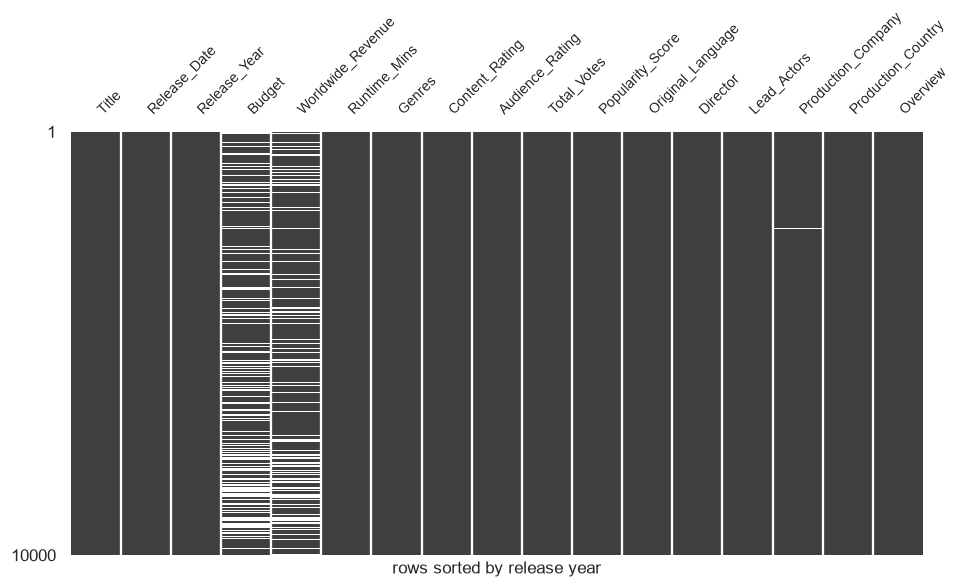

In [28]:
ax = msno.matrix(df.sort_values("Release_Year"), fontsize=9, sparkline=False)
ax.set_xlabel("rows sorted by release year")
fig = plt.gcf()
fig.set_size_inches(10, 5)
save_fig(fig, "fig2_1_missing_matrix")
plt.show()

Rows are sorted by release year, so the vertical gradient in the Budget
column is already a hint: missing financials are not scattered evenly —
they concentrate in particular kinds of films. Tested formally below.

### Step 3 — implausible values

Financial figures from \$1 to \$999 are entry errors or thousands-scale
figures; a runtime of 0 minutes is impossible; the literal director name
`"Name"` is a scraping placeholder. All become NaN. No rows are dropped.

In [29]:
df, floor_counts = clean.floor_financials(df)
df, n_runtime = clean.clean_runtime(df)
df, n_director = clean.fix_director_placeholder(df)
log["budget_floored"] = floor_counts["Budget"]
log["revenue_floored"] = floor_counts["Worldwide_Revenue"]
log["runtime_zeroed"] = n_runtime
log["director_placeholder"] = n_director
print(f"budgets in [1, 999] -> NaN:  {floor_counts['Budget']}")
print(f"revenues in [1, 999] -> NaN: {floor_counts['Worldwide_Revenue']}")
print(f"zero runtimes -> NaN:        {n_runtime}")
print(f"director 'Name' -> NaN:      {n_director}")

budgets in [1, 999] -> NaN:  13
revenues in [1, 999] -> NaN: 9
zero runtimes -> NaN:        1
director 'Name' -> NaN:      1


### Step 4 — duplicates

Four rows are exact copies of another row and are dropped. The remaining
films that share a title and year are *different films* — different
directors, runtimes, languages — so title+year is **not** used as a
dedupe key. The table shows why.

In [30]:
dup_pairs = df[df.duplicated(subset=["Title", "Release_Year"], keep=False) & ~df.duplicated(keep=False)]
dup_pairs.sort_values(["Title", "Release_Year"])[
    ["Title", "Release_Year", "Director", "Runtime_Mins", "Original_Language"]
]

,Title,Release_Year,Director,Runtime_Mins,Original_Language
7490,Return,1972,Arman Manaryan,82.0,hy
9168,Return,1972,David Greig,6.0,en
4410,Return,2015,Haqi Ali,45.0,en
5010,Return,2015,Jon Hyatt,17.0,en
6916,Return,2015,Ryan Heron,15.0,en
7464,Return,2023,Katja Fedulova,61.0,tt
9312,Return,2023,Pete Tolton,92.0,en
6823,Return,<NA>,NaN,18.0,en
8790,Return,<NA>,Malou Reymann,15.0,en
9075,Return,<NA>,Selman Deniz,18.0,hy


In [31]:
df, n_dups = clean.drop_exact_duplicates(df)
log["exact_duplicates_dropped"] = n_dups
log["rows_after_dedupe"] = len(df)
print(f"exact duplicate rows dropped: {n_dups}  ->  {len(df):,} rows remain")

exact duplicate rows dropped: 4  ->  9,996 rows remain


### Step 5 — category hygiene

In [32]:
df, cr_counts = clean.clean_content_rating(df)
df, n_country = clean.normalise_countries(df)
log["content_rating_ws_fixed"] = cr_counts["whitespace_fixed"]
log["content_rating_nr_merged"] = cr_counts["nr_merged"]
log["country_rows_renamed"] = n_country
df["Content_Rating"].value_counts(dropna=False)

Content_Rating
R          4015
PG-13      2370
Unrated    1857
PG         1301
G           405
NC-17        48
Name: count, dtype: int64

### Step 6 — flag unreleased films

Films dated after 2025 cannot have complete revenue. They stay in the
dataset for descriptive counts but are excluded from every financial
analysis via the `is_future` flag.

In [33]:
df, n_future = clean.flag_future(df)
log["future_flagged"] = n_future
print(f"films flagged is_future (year > 2025): {n_future}")

films flagged is_future (year > 2025): 92


### Step 7 — is the missingness random? (MCAR vs MAR)

If financials were missing completely at random, documented and
undocumented films would look alike on every other variable, and median
imputation would be defensible. Compare the two groups on year, votes,
rating, popularity and language. Distributions are heavily skewed, so the
test is Mann-Whitney U (nonparametric), with the rank-biserial correlation
as effect size; language uses a chi-square test on the 2x2 table.

In [34]:
df, n_has_fin = clean.flag_has_financials(df)
log["has_financials"] = n_has_fin

# Released films only: post-2025 films lack revenue for a different reason
# (it does not exist yet) and would bias the comparison toward "newer".
mar = df[~df["is_future"]]
grp = mar["has_financials"]
log["mar_n_doc"] = int(grp.sum())
log["mar_n_undoc"] = int((~grp).sum())
compare_cols = ["Release_Year", "Total_Votes", "Audience_Rating", "Popularity_Score"]

rows = []
for col in compare_cols:
    a = mar.loc[grp, col].dropna().astype("float64")
    b = mar.loc[~grp, col].dropna().astype("float64")
    u, p = sps.mannwhitneyu(a, b, alternative="two-sided")
    rank_biserial = 1 - 2 * u / (len(a) * len(b))
    rows.append(
        {
            "variable": col,
            "median documented": a.median(),
            "median undocumented": b.median(),
            "Mann-Whitney p": p,
            "rank-biserial r": round(rank_biserial, 3),
            "n doc": len(a),
            "n undoc": len(b),
        }
    )
mar_table = pd.DataFrame(rows).set_index("variable")
log["mar_p_year"] = float(mar_table.loc["Release_Year", "Mann-Whitney p"])
log["mar_p_votes"] = float(mar_table.loc["Total_Votes", "Mann-Whitney p"])
log["mar_median_votes_doc"] = float(mar_table.loc["Total_Votes", "median documented"])
log["mar_median_votes_undoc"] = float(mar_table.loc["Total_Votes", "median undocumented"])
log["mar_median_year_doc"] = float(mar_table.loc["Release_Year", "median documented"])
log["mar_median_year_undoc"] = float(mar_table.loc["Release_Year", "median undocumented"])
log["mar_median_pop_doc"] = float(mar_table.loc["Popularity_Score", "median documented"])
log["mar_median_pop_undoc"] = float(mar_table.loc["Popularity_Score", "median undocumented"])
log["mar_median_rating_doc"] = float(mar_table.loc["Audience_Rating", "median documented"])
log["mar_median_rating_undoc"] = float(mar_table.loc["Audience_Rating", "median undocumented"])
log["mar_p_rating"] = float(mar_table.loc["Audience_Rating", "Mann-Whitney p"])
mar_table

,median documented,median undocumented,Mann-Whitney p,rank-biserial r,n doc,n undoc
variable,,,,,,
Release_Year,2007.0000,2015.00000,6.823870e-90,0.247,6560,3341
Total_Votes,1494.0000,608.00000,0.000000e+00,-0.547,6560,3344
Audience_Rating,6.6955,6.70000,1.024527e-01,0.020,6560,3344
Popularity_Score,7.5198,4.74105,0.000000e+00,-0.515,6560,3344


In [35]:
# Language: is a documented film more likely to be in English?
ct = pd.crosstab(mar["Original_Language"] == "en", grp)
chi2, p_lang, dof, _ = sps.chi2_contingency(ct)
pct_en_doc = (mar.loc[grp, "Original_Language"] == "en").mean() * 100
pct_en_undoc = (mar.loc[~grp, "Original_Language"] == "en").mean() * 100
log["mar_p_language"] = float(p_lang)
log["mar_pct_english_doc"] = round(float(pct_en_doc), 1)
log["mar_pct_english_undoc"] = round(float(pct_en_undoc), 1)
print(f"English share, documented:   {pct_en_doc:.1f}%")
print(f"English share, undocumented: {pct_en_undoc:.1f}%")
print(f"chi-square p = {p_lang:.2e}")

# One table for the report: four Mann-Whitney rows plus the language chi-square row
mar_tex = pd.DataFrame(
    {
        "variable": ["release year", "total votes", "audience rating", "popularity score"],
        "median (known)": [f"{v:.0f}" if i == 0 else fmt_int(v) if i == 1 else f"{v:.2f}"
                           for i, v in enumerate(mar_table["median documented"])],
        "median (missing)": [f"{v:.0f}" if i == 0 else fmt_int(v) if i == 1 else f"{v:.2f}"
                             for i, v in enumerate(mar_table["median undocumented"])],
        "test": ["Mann-Whitney U"] * 4,
        "p": [fmt_p(p) for p in mar_table["Mann-Whitney p"]],
        "effect r": [f"{v:+.2f}" for v in mar_table["rank-biserial r"]],
    }
)
mar_tex.loc[len(mar_tex)] = ["% English-language", f"{pct_en_doc:.1f}", f"{pct_en_undoc:.1f}",
                             "chi-square", fmt_p(p_lang), "--"]
write_table(mar_tex, "tab2_3_mar_tests", align="lrrlrr")

English share, documented:   88.3%
English share, undocumented: 63.0%
chi-square p = 2.69e-193


WindowsPath('C:/EDA_Project/movie-success-eda/report/tables/tab2_3_mar_tests.tex')

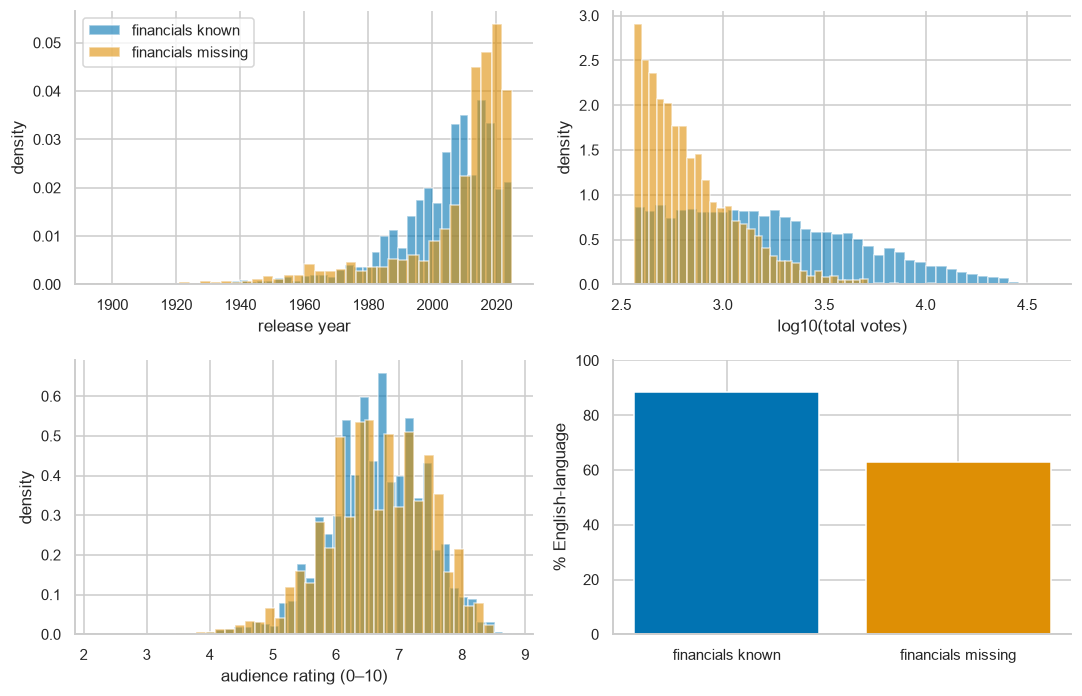

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
labels = {True: "financials known", False: "financials missing"}
colors = {True: "C0", False: "C1"}

for flag in [True, False]:
    sub = mar[grp == flag]
    axes[0, 0].hist(
        sub["Release_Year"].dropna().astype("float64"), bins=40, alpha=0.6,
        density=True, label=labels[flag], color=colors[flag],
    )
    axes[0, 1].hist(
        np.log10(sub["Total_Votes"]), bins=40, alpha=0.6, density=True, color=colors[flag],
    )
    axes[1, 0].hist(
        sub["Audience_Rating"], bins=40, alpha=0.6, density=True, color=colors[flag],
    )
axes[0, 0].set_xlabel("release year")
axes[0, 0].set_ylabel("density")
axes[0, 0].legend()
axes[0, 1].set_xlabel("log10(total votes)")
axes[0, 1].set_ylabel("density")
axes[1, 0].set_xlabel("audience rating (0–10)")
axes[1, 0].set_ylabel("density")

en_share = pd.DataFrame(
    {
        "group": ["financials known", "financials missing"],
        "pct_english": [pct_en_doc, pct_en_undoc],
    }
)
axes[1, 1].bar(en_share["group"], en_share["pct_english"], color=["C0", "C1"])
axes[1, 1].set_ylabel("% English-language")
axes[1, 1].set_ylim(0, 100)

fig.tight_layout()
save_fig(fig, "fig2_2_mar_comparison")
plt.show()

**Decision.** (Numbers in the table above and in `ch02_cleaning.json`.)
Films with missing financials are far less voted-on, less popular and
much less likely to be in English — and they are **newer**, not older.
That contradicts the project brief's expectation that undocumented films
skew old: the gap is driven by recent, small, often non-English or
streaming-era releases whose box office is never published. Audience
rating is the one variable on which the groups do *not* differ
significantly — what is missing is commercial visibility, not quality.

The missingness is therefore not MCAR; it is at best MAR (explained by
votes, popularity, language and year) and plausibly MNAR (films that
earned little are the ones whose figures go unreported). Imputing a
median budget would invent plausible-looking numbers for precisely the
films least like the ones the median came from, so:

- **Complete-case analysis** for everything financial, on the films with
  both budget and revenue known (sample size stated with every statistic).
- **No imputation** of Budget or Worldwide_Revenue, ever.
- Consequence, stated in the report: financial conclusions apply to
  well-documented, mostly mainstream, mostly English-language cinema —
  not to film in general.

### Step 8 — attach the secondary (Kaggle) file

Joined on normalised title + release year. Three permitted uses: recover
the TMDB `id`, cross-validate ratings and popularity, fill the handful of
missing genres and overviews. The two files are never concatenated.

The fill mechanism turns out to fill **nothing**: the three rows with a
missing genre or overview are obscure films all titled "Return" (two of
them with no release year) that do not appear in the Kaggle top-10K file.
The counts below report that honestly rather than pretending the
secondary file rescued them.

In [37]:
df2 = load_secondary()
df, sec_counts = clean.attach_secondary(df, df2)
log.update(
    secondary_matched=sec_counts["matched"],
    genres_filled=sec_counts["genres_filled"],
    overviews_filled=sec_counts["overviews_filled"],
)
print(f"films matched to secondary file: {sec_counts['matched']:,} of {len(df):,}")
print(f"missing genres filled:    {sec_counts['genres_filled']}")
print(f"missing overviews filled: {sec_counts['overviews_filled']}")

films matched to secondary file: 8,417 of 9,996
missing genres filled:    0
missing overviews filled: 0


#### Cross-source validation

Do the two collections agree on the films they share? If the scrape is
sound, the primary `Audience_Rating` and the Kaggle `vote_average` should
be nearly identical, and the two popularity scores should rank films
similarly (popularity is time-sensitive, so exact agreement is not expected).

In [38]:
m = df.dropna(subset=["sec_vote_average"])
r_rating_p, p_rating = sps.pearsonr(m["Audience_Rating"], m["sec_vote_average"])
r_rating_s, _ = sps.spearmanr(m["Audience_Rating"], m["sec_vote_average"])
r_pop_s, p_pop = sps.spearmanr(m["Popularity_Score"], m["sec_popularity"])
log.update(
    crossval_n=len(m),
    crossval_rating_pearson=round(float(r_rating_p), 4),
    crossval_rating_spearman=round(float(r_rating_s), 4),
    crossval_popularity_spearman=round(float(r_pop_s), 4),
)
print(f"shared films: {len(m):,}")
print(f"rating    Pearson r  = {r_rating_p:.4f} (p = {p_rating:.2e})")
print(f"rating    Spearman r = {r_rating_s:.4f}")
print(f"popularity Spearman r = {r_pop_s:.4f} (time-sensitive metric)")

shared films: 8,417
rating    Pearson r  = 0.9919 (p = 0.00e+00)
rating    Spearman r = 0.9917
popularity Spearman r = 0.7025 (time-sensitive metric)


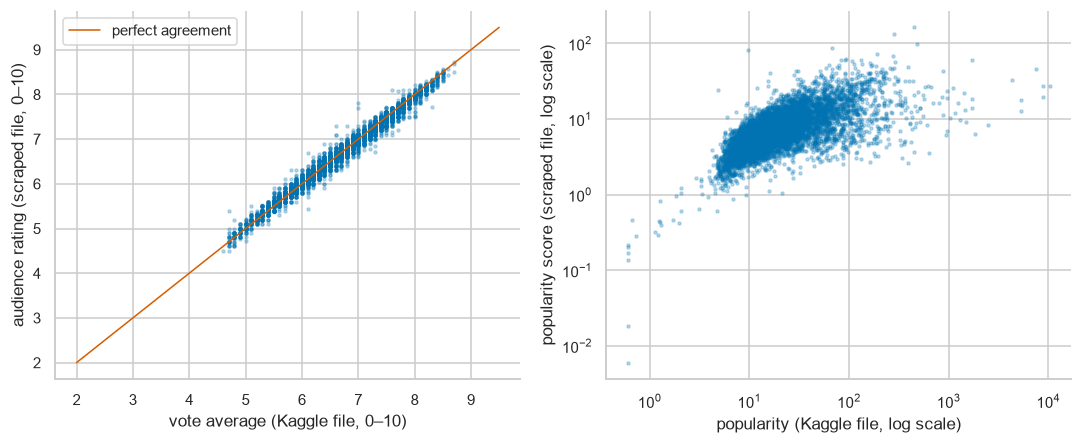

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].scatter(m["sec_vote_average"], m["Audience_Rating"], s=4, alpha=0.25)
axes[0].plot([2, 9.5], [2, 9.5], color="C3", lw=1, label="perfect agreement")
axes[0].set_xlabel("vote average (Kaggle file, 0–10)")
axes[0].set_ylabel("audience rating (scraped file, 0–10)")
axes[0].legend()
axes[1].scatter(m["sec_popularity"], m["Popularity_Score"], s=4, alpha=0.25)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("popularity (Kaggle file, log scale)")
axes[1].set_ylabel("popularity score (scraped file, log scale)")
fig.tight_layout()
save_fig(fig, "fig2_3_crossval")
plt.show()

### Step 9 — inflation adjustment

Nominal dollars across 1895–2026 are not comparable. Both financial
columns are deflated to constant **2025 dollars** with the annual-average
US CPI-U (FRED series `CPIAUCNS`, committed at
`data/raw/cpi_cpiaucns_monthly.csv`). CPI starts in 1913: earlier films
get no deflated value rather than an invented factor, and so do post-2025
films (partial-year CPI, excluded from financial analysis anyway).

In [40]:
cpi = clean.cpi_annual(RAW / "cpi_cpiaucns_monthly.csv")
df["Budget_2025usd"] = clean.deflate(df["Budget"], df["Release_Year"], cpi)
df["Revenue_2025usd"] = clean.deflate(df["Worldwide_Revenue"], df["Release_Year"], cpi)

pre_cpi = int((df["Release_Year"] < 1913).sum())
lost_budget = int((df["Budget"].notna() & df["Budget_2025usd"].isna()).sum())
log["pre_1913_films"] = pre_cpi
log["deflation_lost_budget_values"] = lost_budget
print(f"films before 1913 (no CPI):                  {pre_cpi}")
print(f"known budgets without a deflated value:      {lost_budget}")
lost_usable = int(
    (df["has_financials"] & ~df["is_future"] & df["Budget_2025usd"].isna()).sum()
)
log["deflation_lost_usable"] = lost_usable
print(f"…of which in the usable financial sample:    {lost_usable}")

films before 1913 (no CPI):                  4
known budgets without a deflated value:      64
…of which in the usable financial sample:    0


In [41]:
# Sanity check on familiar titles: nominal vs constant-2025 dollars
chk = df[df["Title"].isin(["Jaws", "Titanic", "Oppenheimer"])].dropna(subset=["Budget"])
chk = chk[["Title", "Release_Year", "Budget", "Budget_2025usd"]].sort_values("Release_Year")
for _, r in chk.iterrows():
    key = r["Title"].lower().replace(" ", "")
    log[f"deflate_{key}_nominal_m"] = round(float(r["Budget"]) / 1e6, 1)
    log[f"deflate_{key}_2025_m"] = round(float(r["Budget_2025usd"]) / 1e6, 1)
log["cpi_base_year"] = clean.CPI_BASE_YEAR
chk.assign(
    Budget=lambda d: (d["Budget"] / 1e6).round(1),
    Budget_2025usd=lambda d: (d["Budget_2025usd"] / 1e6).round(1),
).rename(columns={"Budget": "budget ($M nominal)", "Budget_2025usd": "budget ($M, 2025)"})

,Title,Release_Year,budget ($M nominal),"budget ($M, 2025)"
271,Jaws,1975,7.0,41.9
16,Titanic,1997,200.0,401.1
247,Oppenheimer,2023,100.0,105.7


### Step 10 — reconciliation and output

10,000 rows in; only exact duplicates leave. Everything else is flagged
or NaN'd and excluded per-analysis, never dropped from the file.

In [42]:
usable = df["has_financials"] & ~df["is_future"]
log["rows_out"] = len(df)
log["usable_financial_sample"] = int(usable.sum())

recon = pd.DataFrame(
    [
        ["rows in (raw file)", log["rows_in"]],
        ["exact duplicate rows dropped", -log["exact_duplicates_dropped"]],
        ["rows out (cleaned file)", log["rows_out"]],
        ["  … with budget & revenue known", log["has_financials"]],
        ["  … and released (not future)", log["usable_financial_sample"]],
    ],
    columns=["step", "rows"],
)
recon_tex = recon.copy()
recon_tex["step"] = (
    recon_tex["step"].str.replace("&", "and", regex=False).str.replace("  … ", r"$\quad$ ", regex=False)
)
recon_tex["rows"] = recon_tex["rows"].map(lambda v: ("$-$" + fmt_int(-v)) if v < 0 else fmt_int(v))
write_table(recon_tex, "tab2_4_reconciliation")
recon

,step,rows
0,rows in (raw file),10000
1,exact duplicate rows dropped,-4
2,rows out (cleaned file),9996
3,… with budget & revenue known,6619
4,… and released (not future),6560


In [43]:
INTERIM.mkdir(parents=True, exist_ok=True)
df.to_parquet(INTERIM / "movies_clean.parquet")
out = write_stats("ch02_cleaning", log)
print(f"wrote {INTERIM / 'movies_clean.parquet'}")
print(f"{len(log)} statistics -> {out.relative_to(ROOT)}")

wrote C:\EDA_Project\movie-success-eda\data\interim\movies_clean.parquet
49 statistics -> report\stats\ch02_cleaning.json


### Chapter 2 summary

| Rule | Effect |
|---|---|
| Zero-coded financials -> NaN | 2,814 budgets, 2,288 revenues |
| Floor at \$1,000 | 13 budgets, 9 revenues -> NaN |
| Zero runtime, placeholder director | 1 each -> NaN |
| Exact duplicates | 4 rows dropped (only rows removed) |
| Title+year "duplicates" | kept — verified distinct films |
| `NR` -> `Unrated`, whitespace stripped | one consistent rating scheme |
| `is_future` flag | post-2025 films excluded from financial analysis |
| MCAR/MAR test | missingness strongly non-random -> complete-case, no imputation |
| Secondary join | TMDB id recovered; ratings cross-validated; genres/overviews filled |
| CPI deflation | constant-2025-dollar budget and revenue columns |

The financial analysis sample is **`usable_financial_sample`** films
(budget and revenue known, released by 2025) out of 9,996 — every other
film remains for non-financial analysis.

---
# Part 3 — Univariate visualisation

*Report Chapter 3. Source notebook: `notebooks/03_univariate.ipynb`.*

## 03 — Univariate visualisation

Distributions of every analysis variable, one at a time. Financial
variables are shown on linear **and** log scales — the linear panel exists
precisely to show the skew that makes the log panel necessary. Financial
plots use the complete-case sample (budget and revenue known, released by
2025); everything else uses all 9,996 cleaned films. Sample sizes are
printed on every panel and written to `report/stats/ch03_univariate.json`.

In [44]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.load import load_interim
from src.plotting import apply_style, save_fig
from src.reporting import write_stats

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

stats = {}

df = load_interim("movies_clean")
fin = df[df["has_financials"] & ~df["is_future"]].copy()
stats["n_all"] = len(df)
stats["n_financial"] = len(fin)
print(f"all films: {len(df):,}   financial sample: {len(fin):,}")

all films: 9,996   financial sample: 6,560


### Budget and revenue — linear and log

The linear panels are deliberately kept: they show that both variables
span four orders of magnitude and pile up against zero, which is why every
later financial plot uses a log scale.

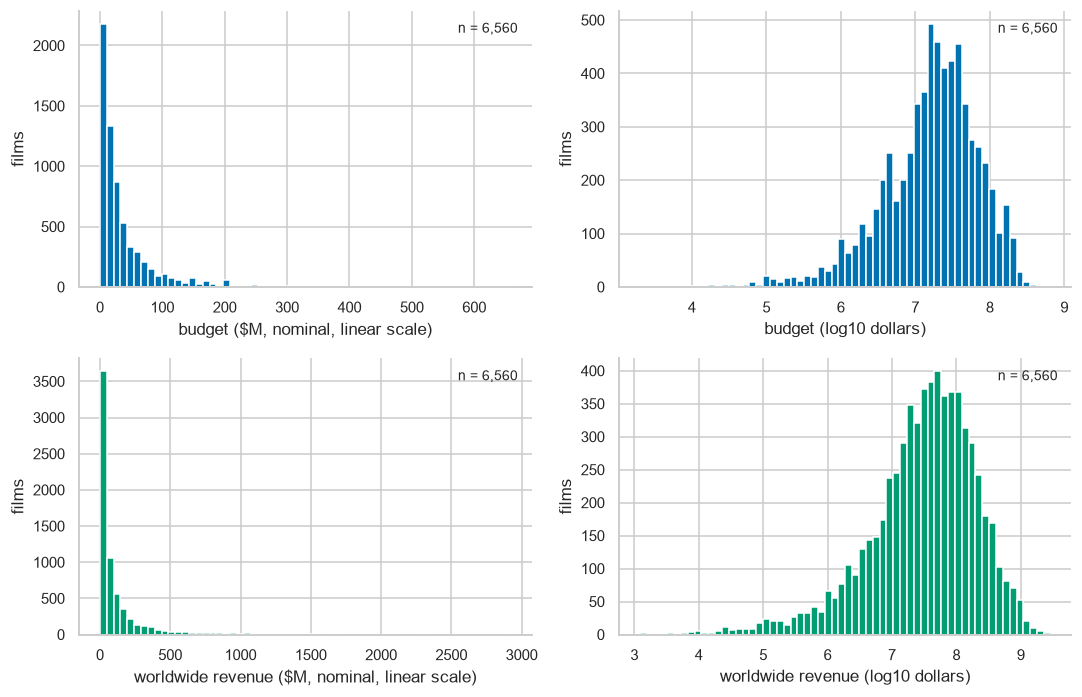

skewness: budget 2.98, revenue 4.84 (log panels are near-symmetric)


In [45]:
budget = fin["Budget"].astype("float64")
revenue = fin["Worldwide_Revenue"].astype("float64")
stats["budget_skew"] = round(float(budget.skew()), 2)
stats["revenue_skew"] = round(float(revenue.skew()), 2)
stats["budget_median"] = float(budget.median())
stats["revenue_median"] = float(revenue.median())

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
axes[0, 0].hist(budget / 1e6, bins=60, color="C0")
axes[0, 0].set_xlabel("budget ($M, nominal, linear scale)")
axes[0, 0].set_ylabel("films")
axes[0, 1].hist(np.log10(budget), bins=60, color="C0")
axes[0, 1].set_xlabel("budget (log10 dollars)")
axes[0, 1].set_ylabel("films")
axes[1, 0].hist(revenue / 1e6, bins=60, color="C2")
axes[1, 0].set_xlabel("worldwide revenue ($M, nominal, linear scale)")
axes[1, 0].set_ylabel("films")
axes[1, 1].hist(np.log10(revenue), bins=60, color="C2")
axes[1, 1].set_xlabel("worldwide revenue (log10 dollars)")
axes[1, 1].set_ylabel("films")
for ax in axes.flat:
    ax.annotate(f"n = {len(fin):,}", xy=(0.97, 0.92), xycoords="axes fraction", ha="right", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig3_1_budget_revenue_dist")
plt.show()
print(f"skewness: budget {stats['budget_skew']}, revenue {stats['revenue_skew']} (log panels are near-symmetric)")

### Runtime, audience rating, release year

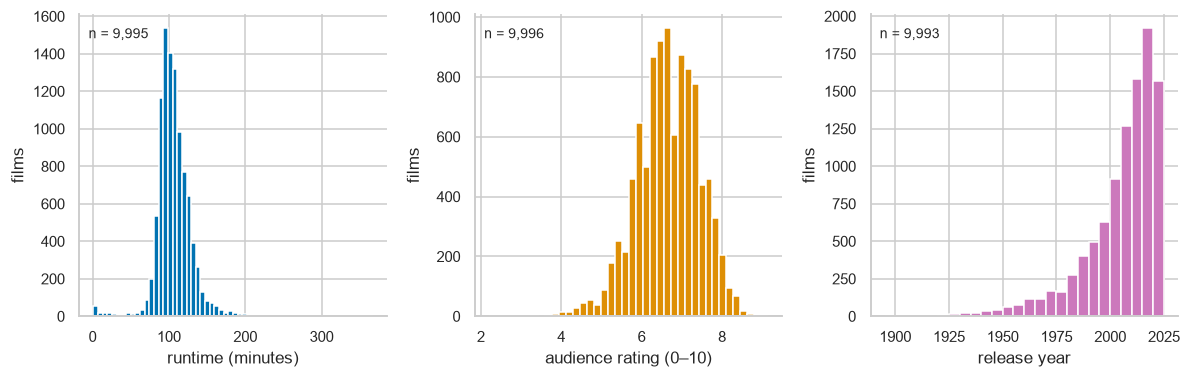

In [46]:
runtime = df["Runtime_Mins"].dropna().astype("float64")
rating = df["Audience_Rating"].dropna().astype("float64")
years = df["Release_Year"].dropna().astype("float64")
stats["runtime_skew"] = round(float(runtime.skew()), 2)
stats["rating_skew"] = round(float(rating.skew()), 2)
stats["rating_mean"] = round(float(rating.mean()), 2)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
axes[0].hist(runtime, bins=60, color="C0")
axes[0].set_xlabel("runtime (minutes)")
axes[0].set_ylabel("films")
axes[1].hist(rating, bins=40, color="C1")
axes[1].set_xlabel("audience rating (0–10)")
axes[1].set_ylabel("films")
axes[2].hist(years, bins=np.arange(1895, 2030, 5), color="C4")
axes[2].set_xlabel("release year")
axes[2].set_ylabel("films")
for ax, n in zip(axes, [len(runtime), len(rating), len(years)]):
    ax.annotate(f"n = {n:,}", xy=(0.03, 0.92), xycoords="axes fraction", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig3_2_runtime_rating_year_dist")
plt.show()

Runtime is mildly right-skewed around a ~104-minute median, with a long
documentary/epic tail. Ratings are near-symmetric around the mid-6s — the
vote filter (min 367 votes) has already removed the worst-rated obscure
films. The year histogram shows the collection is heavily weighted to
post-1990 cinema; whatever we conclude is mostly about the modern industry.

### Films per year, with and without known financials

Shows both the growth of the collection and where the financial
complete-case sample actually comes from.

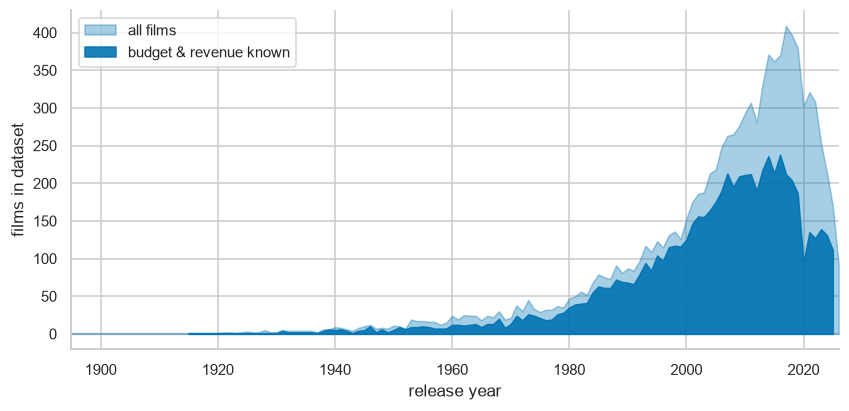

In [47]:
per_year = df.groupby(df["Release_Year"].astype("float64"))["Title"].count()
per_year_fin = fin.groupby(fin["Release_Year"].astype("float64"))["Title"].count()

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(per_year.index, per_year.values, color="C0", alpha=0.35, label="all films")
ax.fill_between(per_year_fin.index, per_year_fin.values, color="C0", alpha=0.9, label="budget & revenue known")
ax.set_xlabel("release year")
ax.set_ylabel("films in dataset")
ax.set_xlim(1895, 2026)
ax.legend()
save_fig(fig, "fig3_3_films_per_year")
stats["pct_films_since_1990"] = round(float((df["Release_Year"] >= 1990).mean()) * 100, 1)
stats["pct_fin_since_1990"] = round(float((fin["Release_Year"] >= 1990).mean()) * 100, 1)
plt.show()

### Genre and language frequency

Genres are multi-label, so films are **exploded**: a film tagged
"Action, Adventure" counts once under each genre, and the bars sum to more
than the number of films. The label order in the raw string is ignored.

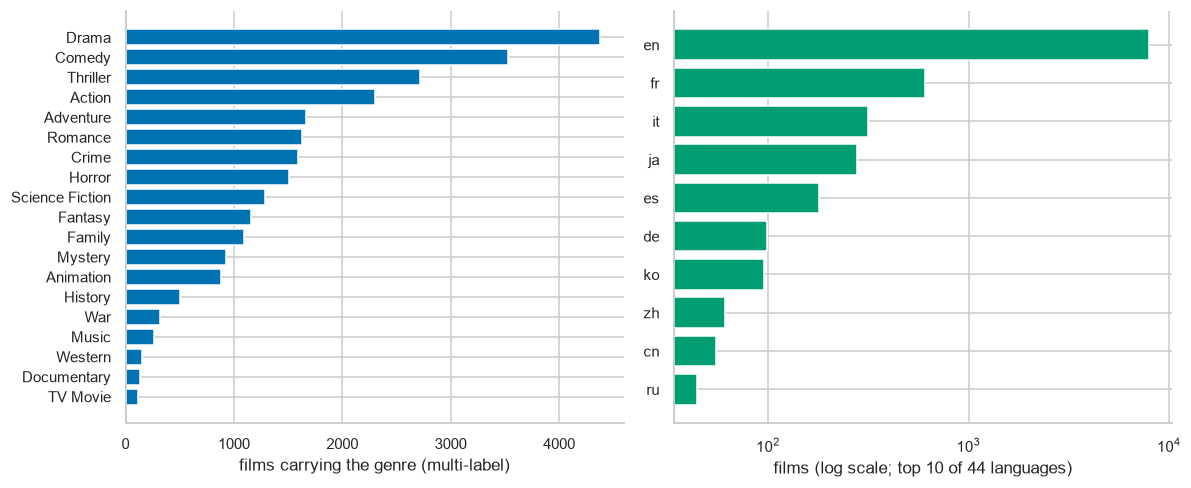

In [48]:
genres = (
    df["Genres"].dropna().str.split(",").explode().str.strip().value_counts()
)
stats["n_genres"] = len(genres)
stats["top_genre"] = genres.index[0]
stats["top_genre_count"] = int(genres.iloc[0])

lang = df["Original_Language"].value_counts()
top_lang = lang.head(10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].barh(genres.index[::-1], genres.values[::-1], color="C0")
axes[0].set_xlabel("films carrying the genre (multi-label)")
axes[1].barh(top_lang.index[::-1], top_lang.values[::-1], color="C2")
axes[1].set_xlabel("films (top 10 of "f"{len(lang)} languages)")
axes[1].set_xscale("log")
axes[1].set_xlabel(f"films (log scale; top 10 of {len(lang)} languages)")
fig.tight_layout()
save_fig(fig, "fig3_4_genre_language_freq")
stats["second_language"] = str(lang.index[1])
stats["second_language_count"] = int(lang.iloc[1])
stats["english_to_second_ratio"] = round(float(lang.iloc[0] / lang.iloc[1]), 1)
stats["n_genre_combinations_raw"] = int(df["Genres"].nunique())
plt.show()

Drama dominates, as it does in every large film collection; the language
panel needs a log scale because English outnumbers the second language
(French) by more than ten to one (exact ratio in the stats JSON) — a
visual reminder of how Anglophone this sample is.

### Content rating

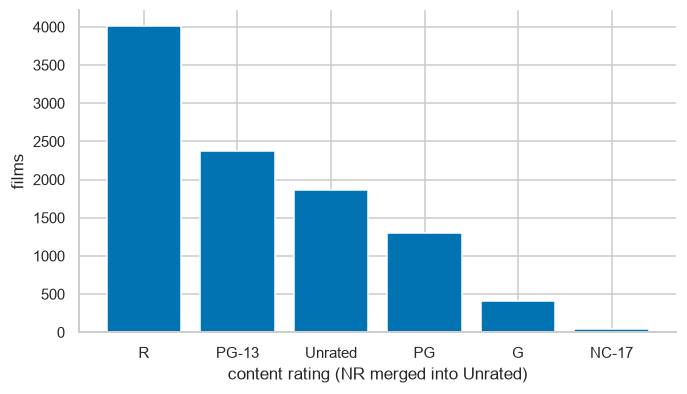

Content_Rating
R          4015
PG-13      2370
Unrated    1857
PG         1301
G           405
NC-17        48
Name: count, dtype: int64

In [49]:
cr = df["Content_Rating"].value_counts(dropna=False)
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = [str(x) for x in cr.index]
ax.bar(labels, cr.values, color="C0")
ax.set_xlabel("content rating (NR merged into Unrated)")
ax.set_ylabel("films")
save_fig(fig, "fig3_5_content_rating")
plt.show()
stats["top_content_rating"] = str(cr.index[0])
stats["top_content_rating_count"] = int(cr.iloc[0])
stats["runtime_median"] = float(runtime.median())
cr

In [50]:
out = write_stats("ch03_univariate", stats)
print(f"{len(stats)} statistics written to {out.relative_to(ROOT)}")
stats

21 statistics written to report\stats\ch03_univariate.json


{'n_all': 9996,
 'n_financial': 6560,
 'budget_skew': 2.98,
 'revenue_skew': 4.84,
 'budget_median': 20000000.0,
 'revenue_median': 39197782.5,
 'runtime_skew': 0.25,
 'rating_skew': -0.33,
 'rating_mean': 6.66,
 'pct_films_since_1990': 84.8,
 'pct_fin_since_1990': 84.3,
 'n_genres': 19,
 'top_genre': 'Drama',
 'top_genre_count': 4376,
 'second_language': 'fr',
 'second_language_count': 608,
 'english_to_second_ratio': 13.1,
 'n_genre_combinations_raw': 2101,
 'top_content_rating': 'R',
 'top_content_rating_count': 4015,
 'runtime_median': 104.0}

---
# Part 4 — Multivariate visualisation

*Report Chapter 3. Source notebook: `notebooks/04_multivariate.ipynb`.*

## 04 — Multivariate visualisation

Relationships between film attributes and the two success measures:
commercial (revenue, ROI) and critical (audience rating). All financial
analysis uses the complete-case sample — budget and revenue known and
plausible, released by 2025 — with the sample size on every figure.
`ROI = revenue / budget` is computed here ad hoc for plotting; Chapter 4
formalises it as an engineered feature. ROI is a ratio of same-year
dollars, so it is identical for nominal and deflated figures.

Every correlation is reported with its p-value and n, and written to
`report/stats/ch03_multivariate.json`.

In [51]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats as sps

from src.load import load_interim
from src.plotting import apply_style, save_fig
from src.reporting import fmt_int, fmt_money_m, fmt_p, write_stats, write_table

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

stats = {}

df = load_interim("movies_clean")
fin = df[df["has_financials"] & ~df["is_future"]].copy()
for c in ["Budget", "Worldwide_Revenue"]:
    fin[c] = fin[c].astype("float64")
fin["roi"] = fin["Worldwide_Revenue"] / fin["Budget"]
fin["log_budget"] = np.log10(fin["Budget"])
fin["log_revenue"] = np.log10(fin["Worldwide_Revenue"])
stats["n_financial"] = len(fin)
print(f"financial sample: {len(fin):,}")

financial sample: 6,560


### Budget vs revenue, log-log, with the break-even line

The dashed line is `revenue = budget`: films below it did not recoup their
production budget from worldwide gross (marketing costs would push the
true break-even line higher still — marketing spend is not in the data).

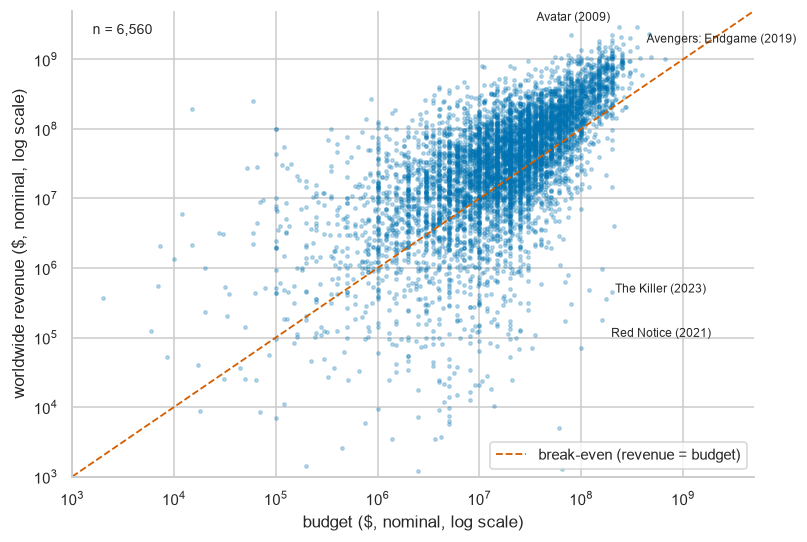

Pearson r (log-log) = 0.638 (p = 0.0e+00), Spearman r = 0.675, n = 6,560
films below break-even on production budget alone: 26.5%


In [52]:
r_p, p_p = sps.pearsonr(fin["log_budget"], fin["log_revenue"])
r_s, p_s = sps.spearmanr(fin["Budget"], fin["Worldwide_Revenue"])
below = (fin["roi"] < 1).mean() * 100
stats.update(
    budget_revenue_pearson_loglog=round(float(r_p), 3),
    budget_revenue_pearson_p=float(p_p),
    budget_revenue_spearman=round(float(r_s), 3),
    pct_below_breakeven=round(float(below), 1),
)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(fin["Budget"], fin["Worldwide_Revenue"], s=5, alpha=0.25)
lims = [1e3, 5e9]
ax.plot(lims, lims, ls="--", color="C3", lw=1.2, label="break-even (revenue = budget)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(*lims)
ax.set_ylim(*lims)
ax.set_xlabel("budget ($, nominal, log scale)")
ax.set_ylabel("worldwide revenue ($, nominal, log scale)")

# annotate the extremes by title instead of dropping them
top_rev = fin.nlargest(2, "Worldwide_Revenue")
# sorted by revenue so the lower point's label goes below it and the higher one's above
flops = fin[fin["Budget"] > 1e8].nsmallest(2, "roi").sort_values("Worldwide_Revenue")
# (offset in points, horizontal alignment) per label, so neighbours don't collide
placement = [((-6, 4), "right"), ((6, -10), "left"), ((6, -11), "left"), ((6, 4), "left")]
for (_, r), (off, ha) in zip(pd.concat([top_rev, flops]).iterrows(), placement):
    ax.annotate(
        f'{r["Title"]} ({int(r["Release_Year"])})',
        xy=(r["Budget"], r["Worldwide_Revenue"]),
        xytext=off, textcoords="offset points", fontsize=8, ha=ha,
    )
ax.annotate(f"n = {len(fin):,}", xy=(0.03, 0.95), xycoords="axes fraction", fontsize=9)
ax.legend(loc="lower right")
save_fig(fig, "fig3_6_budget_vs_revenue")
# Round-number budgets (vertical stripes in the plot): share of budgets that are a
# whole multiple of $1M — reporting heaping, a data-quality signal
stats["pct_budgets_round_million"] = round(float((fin["Budget"] % 1_000_000 == 0).mean()) * 100, 1)
stats["annotated_titles"] = [f'{r["Title"]} ({int(r["Release_Year"])})'
                             for _, r in pd.concat([top_rev, flops]).iterrows()]
for i, (_, r) in enumerate(flops.iterrows(), start=1):
    stats[f"flop_title_{['a', 'b'][i - 1]}"] = f'{r["Title"]} ({int(r["Release_Year"])})'
    stats[f"flop_revenue_{['a', 'b'][i - 1]}"] = float(r["Worldwide_Revenue"])
    stats[f"flop_budget_{['a', 'b'][i - 1]}"] = float(r["Budget"])
for i, (_, r) in enumerate(top_rev.iterrows(), start=1):
    stats[f"top_title_{['a', 'b'][i - 1]}"] = f'{r["Title"]} ({int(r["Release_Year"])})'
plt.show()
print(f"Pearson r (log-log) = {r_p:.3f} (p = {p_p:.1e}), Spearman r = {r_s:.3f}, n = {len(fin):,}")
print(f"films below break-even on production budget alone: {below:.1f}%")

### ROI by genre — and the budget distribution behind it

Multi-label genres are exploded, so a film counts in each of its genres.
Genres with fewer than 100 financially-documented films are dropped from
this plot. ROI is on a log scale; the right panel shows each genre's
budget distribution, because genre ROI and genre budget are entangled
(Simpson's paradox risk) — horror's famous ratios sit on the smallest
denominators in the table, so medians and means must be read together.

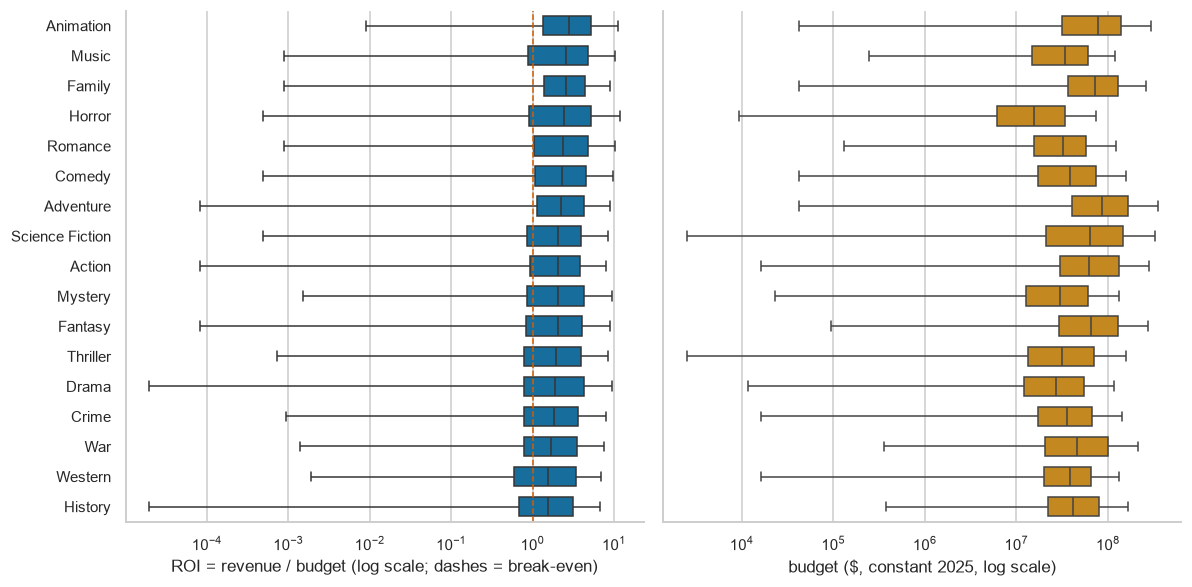

,n,median_roi,mean_roi,median_budget_2025
Genre,,,,
Animation,433,2.83,6.84,76973492.31
Music,173,2.58,5.53,33761164.29
Family,714,2.56,5.06,71819954.32
Horror,957,2.43,26.39,15394698.46
Romance,1083,2.34,4.74,31940109.96
Comedy,2266,2.30,4.83,38030827.25
Adventure,1266,2.26,4.35,85297245.93
Science Fiction,861,2.08,4.81,63045288.23
Action,1664,2.06,4.63,62331350.77


In [53]:
g = fin.copy()
g["Genre"] = g["Genres"].str.split(",")
g = g.explode("Genre")
g["Genre"] = g["Genre"].str.strip()
counts = g["Genre"].value_counts()
keep = counts[counts >= 100].index
g = g[g["Genre"].isin(keep)]
order = g.groupby("Genre")["roi"].median().sort_values(ascending=False).index

roi_table = (
    g.groupby("Genre")
    .agg(n=("roi", "size"), median_roi=("roi", "median"), mean_roi=("roi", "mean"),
         median_budget_2025=("Budget_2025usd", "median"))
    .loc[order]
    .round(2)
)
stats["genre_top_median_roi"] = str(order[0])
stats["genre_top_median_roi_value"] = float(roi_table.iloc[0]["median_roi"])
stats["genre_bottom_median_roi"] = str(order[-1])
stats["genre_min_n"] = 100

# The outliers that explode the Horror/Mystery means, named rather than hidden
top_roi = fin.nlargest(2, "roi")
stats["roi_outliers"] = [
    f'{r["Title"]} ({int(r["Release_Year"])}): ROI {r["roi"]:,.0f} on ${r["Budget"]:,.0f}'
    for _, r in top_roi.iterrows()
]
stats["horror_mean_roi"] = float(roi_table.loc["Horror", "mean_roi"])
stats["horror_median_roi"] = float(roi_table.loc["Horror", "median_roi"])

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
sns.boxplot(data=g, y="Genre", x="roi", order=order, ax=axes[0],
            showfliers=False, color="C0", width=0.65)
axes[0].set_xscale("log")
axes[0].axvline(1, ls="--", color="C3", lw=1)
axes[0].set_xlabel("ROI = revenue / budget (log scale; dashes = break-even)")
axes[0].set_ylabel(None)
sns.boxplot(data=g, y="Genre", x="Budget_2025usd", order=order, ax=axes[1],
            showfliers=False, color="C1", width=0.65)
axes[1].set_xscale("log")
axes[1].set_xlabel("budget ($, constant 2025, log scale)")
axes[1].set_ylabel(None)
fig.tight_layout()
save_fig(fig, "fig3_7_roi_by_genre")
plt.show()

roi_tex = roi_table.reset_index().rename(columns={"Genre": "genre"})
roi_tex = pd.DataFrame(
    {
        "genre": roi_tex["genre"],
        "n": roi_tex["n"].map(fmt_int),
        "median ROI": roi_tex["median_roi"].map(lambda v: f"{v:.2f}"),
        "mean ROI": roi_tex["mean_roi"].map(lambda v: f"{v:.2f}"),
        "median budget (2025 \\$M)": roi_tex["median_budget_2025"].map(fmt_money_m),
    }
)
write_table(roi_tex, "tab3_1_roi_by_genre")
stats["animation_median_budget_m"] = round(float(roi_table.loc["Animation", "median_budget_2025"]) / 1e6, 1)
stats["horror_median_budget_m"] = round(float(roi_table.loc["Horror", "median_budget_2025"]) / 1e6, 1)
stats["mystery_mean_roi"] = float(roi_table.loc["Mystery", "mean_roi"])
stats["mystery_median_roi"] = float(roi_table.loc["Mystery", "median_roi"])
stats["history_median_roi"] = float(roi_table.loc["History", "median_roi"])
roi_table

**A result that contradicts the folk wisdom.** Horror does *not* top the
median ROI table — **Animation** (2.83), Music and Family do, despite
animation carrying one of the *largest* median budgets. Horror is
mid-table by median (2.43) but has by far the most extreme mean (26.4 vs
a 2.43 median), and Mystery's mean is even wilder (32.7): both are
inflated by the same two micro-budget outliers, *Paranormal Activity*
(ROI ≈ 12,890 on a \$15k budget) and *The Blair Witch Project*
(ROI ≈ 4,144), each tagged Horror **and** Mystery. The "horror is the
best bet" story is a mean artifact; the typical horror film clears a low
bar on a tiny denominator. Mean ROI is far above median ROI in every
genre, which is why the table reports both.

### Rating vs revenue

Critical and commercial success are expected to be only weakly related —
that weakness is itself a finding.

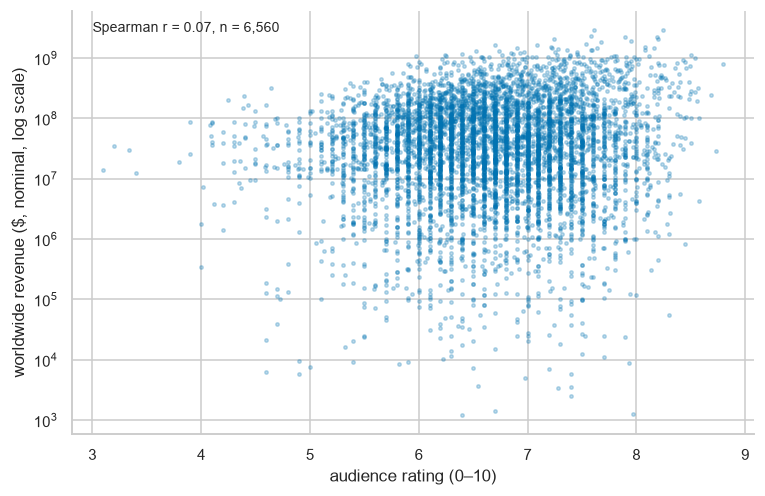

Spearman r = 0.074 (p = 2.1e-09), n = 6,560


In [54]:
r_s2, p_s2 = sps.spearmanr(fin["Audience_Rating"], fin["Worldwide_Revenue"])
stats.update(rating_revenue_spearman=round(float(r_s2), 3), rating_revenue_p=float(p_s2))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fin["Audience_Rating"], fin["Worldwide_Revenue"], s=5, alpha=0.25)
ax.set_yscale("log")
ax.set_xlabel("audience rating (0–10)")
ax.set_ylabel("worldwide revenue ($, nominal, log scale)")
ax.annotate(f"Spearman r = {r_s2:.2f}, n = {len(fin):,}",
            xy=(0.03, 0.95), xycoords="axes fraction", fontsize=9)
save_fig(fig, "fig3_8_rating_vs_revenue")
plt.show()
print(f"Spearman r = {r_s2:.3f} (p = {p_s2:.1e}), n = {len(fin):,}")

### Release month vs revenue

Tests the folk wisdom of the summer and holiday windows. Months are
compared with a Kruskal-Wallis test (revenue is far from normal), and the
figure shows the median with the interquartile range rather than a mean.

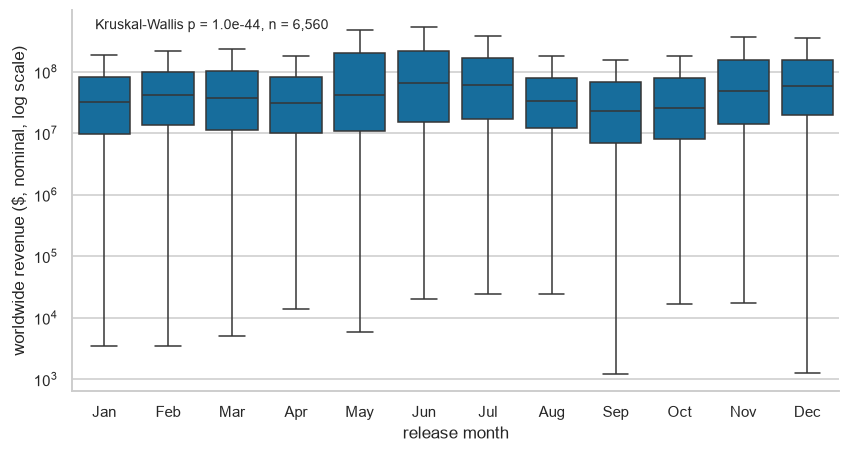

month
1     32.5
2     41.0
3     37.7
4     30.5
5     42.0
6     65.4
7     60.0
8     33.6
9     22.5
10    25.8
11    47.6
12    58.5
Name: median revenue ($M), dtype: float64

In [55]:
m = fin.dropna(subset=["Release_Date"]).copy()
m["month"] = m["Release_Date"].dt.month
kw = sps.kruskal(*[grp["Worldwide_Revenue"].values for _, grp in m.groupby("month")])
med = m.groupby("month")["Worldwide_Revenue"].median()
stats.update(
    month_kruskal_p=float(kw.pvalue),
    best_month=int(med.idxmax()),
    best_month_median=float(med.max()),
    worst_month=int(med.idxmin()),
    worst_month_median=float(med.min()),
)

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=m, x="month", y="Worldwide_Revenue", showfliers=False, color="C0", ax=ax)
ax.set_yscale("log")
ax.set_xticks(range(12), month_names)
ax.set_xlabel("release month")
ax.set_ylabel("worldwide revenue ($, nominal, log scale)")
ax.annotate(f"Kruskal-Wallis p = {kw.pvalue:.1e}, n = {len(m):,}",
            xy=(0.03, 0.95), xycoords="axes fraction", fontsize=9)
save_fig(fig, "fig3_9_month_vs_revenue")
plt.show()
stats["n_month"] = len(m)
stats["july_median"] = float(med.loc[7])
stats["december_median"] = float(med.loc[12])
stats["june_to_september_ratio"] = round(float(med.loc[6] / med.loc[9]), 2)
(med / 1e6).round(1).rename("median revenue ($M)")

### Correlation heatmap

Spearman rank correlations — the financial variables are too skewed for
Pearson to be meaningful on raw dollars. Computed on the financial sample
so every cell shares the same n.

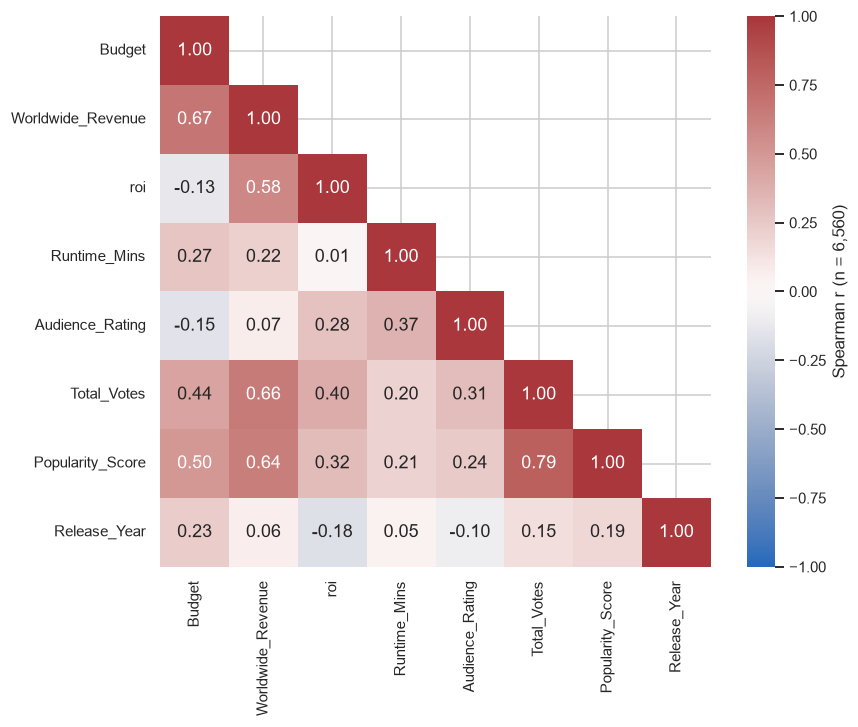

In [56]:
num_cols = ["Budget", "Worldwide_Revenue", "roi", "Runtime_Mins", "Audience_Rating",
            "Total_Votes", "Popularity_Score", "Release_Year"]
corr = fin[num_cols].astype("float64").corr(method="spearman")
stats["roi_budget_spearman"] = round(float(corr.loc["roi", "Budget"]), 3)
stats["votes_revenue_spearman"] = round(float(corr.loc["Total_Votes", "Worldwide_Revenue"]), 3)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"label": f"Spearman r (n = {len(fin):,})"}, ax=ax)
save_fig(fig, "fig3_10_corr_heatmap")
stats["rating_votes_spearman"] = round(float(corr.loc["Audience_Rating", "Total_Votes"]), 3)
stats["budget_year_spearman"] = round(float(corr.loc["Budget", "Release_Year"]), 3)
# p-values for the heatmap's headline cells (n identical for every cell)
_, p_rb = sps.spearmanr(fin["roi"], fin["Budget"])
stats["roi_budget_spearman_p"] = float(p_rb)
plt.show()

### Runtime vs rating

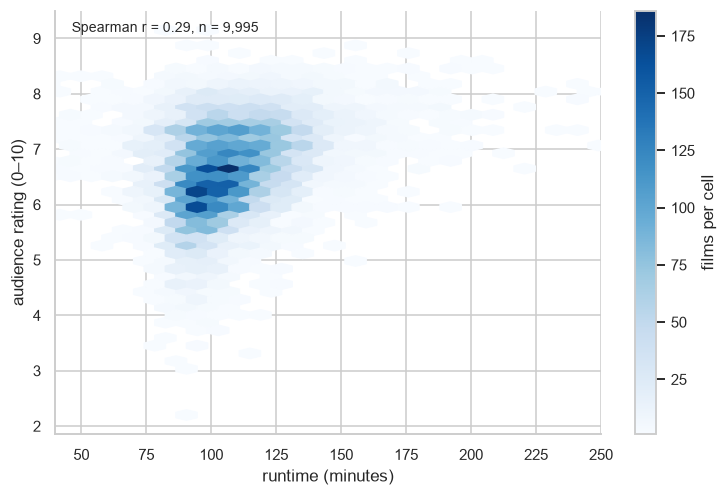

Spearman r = 0.292 (p = 2.5e-196), n = 9,995


In [57]:
rr = df.dropna(subset=["Runtime_Mins", "Audience_Rating"]).copy()
r_s3, p_s3 = sps.spearmanr(rr["Runtime_Mins"].astype("float64"), rr["Audience_Rating"])
stats.update(runtime_rating_spearman=round(float(r_s3), 3), runtime_rating_p=float(p_s3),
             runtime_rating_n=len(rr))

fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(rr["Runtime_Mins"].astype("float64"), rr["Audience_Rating"].astype("float64"),
               gridsize=45, cmap="Blues", mincnt=1)
ax.set_xlim(40, 250)
ax.set_xlabel("runtime (minutes)")
ax.set_ylabel("audience rating (0–10)")
fig.colorbar(hb, ax=ax, label="films per cell")
ax.annotate(f"Spearman r = {r_s3:.2f}, n = {len(rr):,}",
            xy=(0.03, 0.95), xycoords="axes fraction", fontsize=9)
save_fig(fig, "fig3_11_runtime_vs_rating")
plt.show()
print(f"Spearman r = {r_s3:.3f} (p = {p_s3:.1e}), n = {len(rr):,}")

### Budget and ROI by decade, in constant 2025 dollars

Deflated budgets make decades comparable; ROI needs no deflation (the
factor cancels in the ratio). Decades before 1940 have too few documented
films to plot honestly and are listed in the table instead.

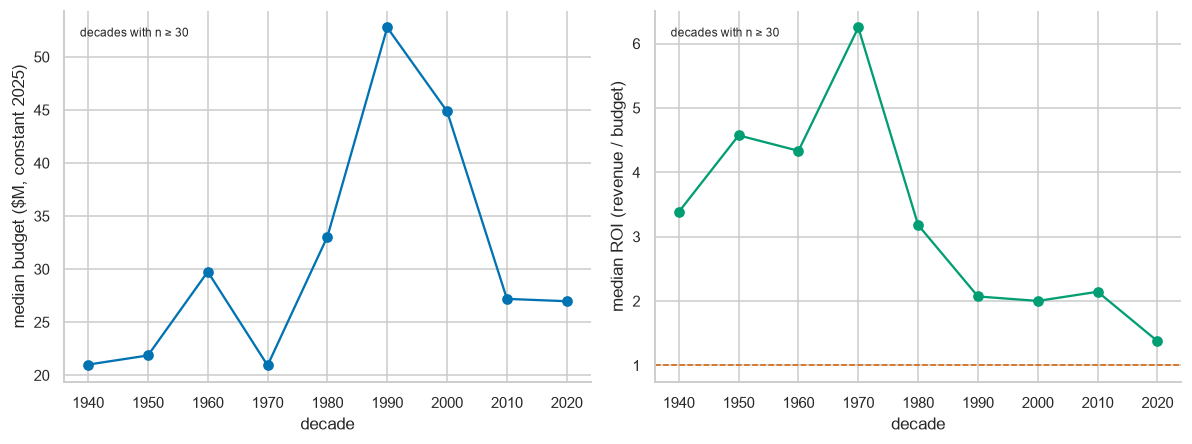

,n,median_budget_2025,median_roi
decade,,,
1910,2,7300276.05,502.27
1920,6,9075329.07,2.83
1930,26,17803870.23,2.76
1940,45,21005775.28,3.38
1950,78,21865970.22,4.57
1960,123,29755964.06,4.33
1970,217,20931716.50,6.25
1980,536,33067893.80,3.18
1990,940,52771272.12,2.07


In [58]:
d = fin.dropna(subset=["Budget_2025usd"]).copy()
d["decade"] = (d["Release_Year"].astype("float64") // 10 * 10).astype(int)
by_dec = d.groupby("decade").agg(
    n=("roi", "size"),
    median_budget_2025=("Budget_2025usd", "median"),
    median_roi=("roi", "median"),
)
by_dec_plot = by_dec[by_dec["n"] >= 30]
stats["decade_table"] = by_dec.reset_index().to_dict("records")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(by_dec_plot.index, by_dec_plot["median_budget_2025"] / 1e6, marker="o", color="C0")
axes[0].set_xlabel("decade")
axes[0].set_ylabel("median budget ($M, constant 2025)")
axes[1].plot(by_dec_plot.index, by_dec_plot["median_roi"], marker="o", color="C2")
axes[1].axhline(1, ls="--", color="C3", lw=1)
axes[1].set_xlabel("decade")
axes[1].set_ylabel("median ROI (revenue / budget)")
for ax in axes:
    ax.annotate("decades with n ≥ 30", xy=(0.03, 0.93), xycoords="axes fraction", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig3_12_decade_trends")
plt.show()

for dec in [1970, 1990, 2010, 2020]:
    stats[f"decade_{dec}_median_budget_m"] = round(float(by_dec.loc[dec, "median_budget_2025"]) / 1e6, 1)
    stats[f"decade_{dec}_median_roi"] = round(float(by_dec.loc[dec, "median_roi"]), 2)
    stats[f"decade_{dec}_n"] = int(by_dec.loc[dec, "n"])

dec_tex = by_dec.reset_index()
dec_tex = pd.DataFrame(
    {
        "decade": dec_tex["decade"].map(lambda d: f"{d}s"),
        "n": dec_tex["n"].map(fmt_int),
        "median budget (2025 \\$M)": dec_tex["median_budget_2025"].map(fmt_money_m),
        "median ROI": dec_tex["median_roi"].map(lambda v: f"{v:.2f}"),
    }
)
write_table(dec_tex, "tab3_2_decades")
by_dec.round(2)

### Chapter 1 question — which genres have the best ratio of rating to cost?

For each genre (exploded, >= 100 documented films), the median audience
rating and the median constant-2025 budget. "Value" is the median rating
per \$10M of median budget. The ratio is dominated by its denominator, so
the scatter is the more honest reading: genres up and to the left give
more rating for less money.

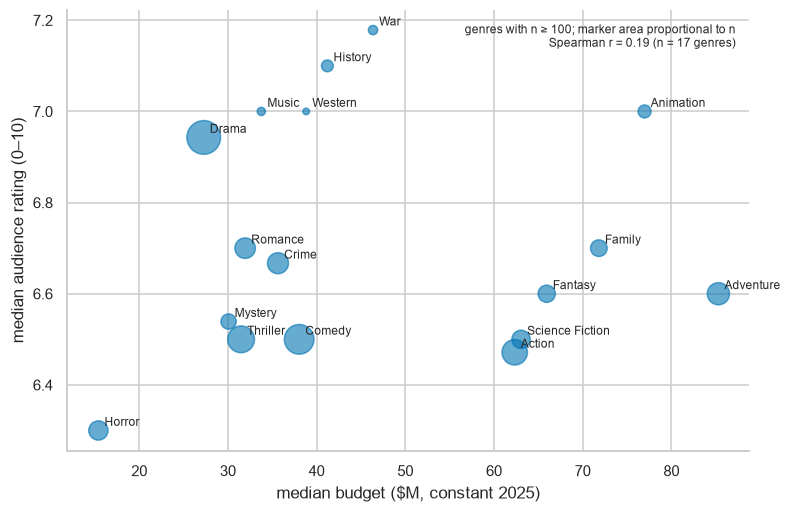

,n,median_rating,median_budget_2025,rating_per_10m
Genre,,,,
Horror,957,6.30,15394698.46,4.09
Drama,2921,6.94,27271267.98,2.55
Mystery,602,6.54,30072522.05,2.17
Romance,1083,6.70,31940109.96,2.10
Music,173,7.00,33761164.29,2.07
Thriller,1844,6.50,31481875.65,2.06
Crime,1137,6.67,35643425.14,1.87
Western,111,7.00,38817792.95,1.80
History,359,7.10,41213100.06,1.72


In [59]:
val = (
    g.groupby("Genre")
    .agg(n=("roi", "size"), median_rating=("Audience_Rating", "median"),
         median_budget_2025=("Budget_2025usd", "median"))
)
val["rating_per_10m"] = val["median_rating"] / (val["median_budget_2025"] / 1e7)
val = val.sort_values("rating_per_10m", ascending=False)
r_gv, p_gv = sps.spearmanr(val["median_budget_2025"], val["median_rating"])
stats.update(
    value_top_genre=str(val.index[0]),
    value_top_ratio=round(float(val["rating_per_10m"].iloc[0]), 2),
    value_second_genre=str(val.index[1]),
    value_bottom_genre=str(val.index[-1]),
    value_bottom_ratio=round(float(val["rating_per_10m"].iloc[-1]), 2),
    value_top_rating_genre=str(val["median_rating"].idxmax()),
    value_top_rating=round(float(val["median_rating"].max()), 2),
    genre_budget_rating_spearman=round(float(r_gv), 3),
    genre_budget_rating_p=float(p_gv),
    genre_budget_rating_n=len(val),
)

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.scatter(val["median_budget_2025"] / 1e6, val["median_rating"], s=val["n"] / 6, alpha=0.6, color="C0")
for name, r in val.iterrows():
    ax.annotate(name, (r["median_budget_2025"] / 1e6, r["median_rating"]),
                xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("median budget ($M, constant 2025)")
ax.set_ylabel("median audience rating (0–10)")
ax.annotate(f"genres with n ≥ 100; marker area proportional to n\nSpearman r = {r_gv:.2f} (n = {len(val)} genres)",
            xy=(0.98, 0.97), xycoords="axes fraction", fontsize=8, ha="right", va="top")
save_fig(fig, "fig3_13_genre_value")
plt.show()

val_tex = val.reset_index()
val_tex = pd.DataFrame(
    {
        "genre": val_tex["Genre"],
        "n": val_tex["n"].map(fmt_int),
        "median rating": val_tex["median_rating"].map(lambda v: f"{v:.2f}"),
        "median budget (2025 \\$M)": val_tex["median_budget_2025"].map(fmt_money_m),
        "rating per \\$10M": val_tex["rating_per_10m"].map(lambda v: f"{v:.2f}"),
    }
)
write_table(val_tex, "tab3_3_genre_value")
val.round(2)

### Chapter 1 question — has mid-budget profitability changed since 2000?

"Mid-budget" is fixed by convention before looking at outcomes: a
constant-2025 budget between \$20M and \$80M. Periods: 2000–09, 2010–19,
2020–25. ROI across periods is compared with Kruskal-Wallis and the
profitable share with a chi-square test. The 2020s include the pandemic
collapse of theatrical release and are flagged as such.

In [60]:
mid = fin[(fin["Budget_2025usd"] >= 20e6) & (fin["Budget_2025usd"] <= 80e6)
          & (fin["Release_Year"] >= 2000)].copy()
mid["period"] = pd.cut(mid["Release_Year"].astype("float64"), [1999, 2009, 2019, 2025],
                       labels=["2000–09", "2010–19", "2020–25"])
mid["profitable"] = mid["roi"] > 1
by_period = mid.groupby("period", observed=True).agg(
    n=("roi", "size"), median_roi=("roi", "median"), pct_profitable=("profitable", "mean"),
)
by_period["pct_profitable"] *= 100
kw_mid = sps.kruskal(*[grp["roi"].values for _, grp in mid.groupby("period", observed=True)])
chi_mid = sps.chi2_contingency(pd.crosstab(mid["period"], mid["profitable"]))
mw_mid = sps.mannwhitneyu(mid.loc[mid["period"] == "2000–09", "roi"],
                          mid.loc[mid["period"] == "2010–19", "roi"], alternative="two-sided")
stats.update(
    mid_n=len(mid),
    mid_roi_2000s=round(float(by_period.loc["2000–09", "median_roi"]), 2),
    mid_roi_2010s=round(float(by_period.loc["2010–19", "median_roi"]), 2),
    mid_roi_2020s=round(float(by_period.loc["2020–25", "median_roi"]), 2),
    mid_pct_prof_2000s=round(float(by_period.loc["2000–09", "pct_profitable"]), 1),
    mid_pct_prof_2010s=round(float(by_period.loc["2010–19", "pct_profitable"]), 1),
    mid_pct_prof_2020s=round(float(by_period.loc["2020–25", "pct_profitable"]), 1),
    mid_n_2000s=int(by_period.loc["2000–09", "n"]),
    mid_n_2010s=int(by_period.loc["2010–19", "n"]),
    mid_n_2020s=int(by_period.loc["2020–25", "n"]),
    mid_kruskal_p=float(kw_mid.pvalue),
    mid_chi2_p=float(chi_mid.pvalue),
    mid_2000s_vs_2010s_p=float(mw_mid.pvalue),
)
mid_tex = by_period.reset_index()
mid_tex = pd.DataFrame(
    {
        "period": mid_tex["period"].astype(str).str.replace("–", "--", regex=False),
        "n": mid_tex["n"].map(fmt_int),
        "median ROI": mid_tex["median_roi"].map(lambda v: f"{v:.2f}"),
        "% profitable": mid_tex["pct_profitable"].map(lambda v: f"{v:.1f}"),
    }
)
write_table(mid_tex, "tab3_4_mid_budget")
print(f"Kruskal-Wallis on ROI across periods: p = {kw_mid.pvalue:.2e}")
print(f"chi-square on profitable share:       p = {chi_mid.pvalue:.2e}")
print(f"2000s vs 2010s only (Mann-Whitney):   p = {mw_mid.pvalue:.3f}")
by_period.round(2)

Kruskal-Wallis on ROI across periods: p = 2.47e-10
chi-square on profitable share:       p = 3.91e-10
2000s vs 2010s only (Mann-Whitney):   p = 0.879


,n,median_roi,pct_profitable
period,,,
2000–09,785,1.78,70.45
2010–19,829,1.89,69.96
2020–25,279,1.00,50.18


In [61]:
out = write_stats("ch03_multivariate", stats)
print(f"{len(stats)} statistics written to {out.relative_to(ROOT)}")

82 statistics written to report\stats\ch03_multivariate.json


### What Chapter 3 found (carried to the report)

- Budget and revenue are strongly associated on the log-log scale, but a
  large minority of films sit below even the production-budget break-even
  line — before marketing costs.
- Genre ROI differences are inseparable from genre budget differences:
  the high-ROI genres are the cheap ones. Mean ROI is uninformative
  without the median beside it.
- Rating and revenue are only weakly rank-correlated: commercial and
  critical success are substantially different outcomes.
- Genre "value" (rating per dollar) is led by the low-budget genres,
  while across genres median budget and median rating are essentially
  unrelated. Mid-budget profitability was flat from the 2000s to the
  2010s and fell in 2020–25. Exact figures are in the stats JSON and
  quoted in Chapter 6.
- Release month matters (Kruskal-Wallis p ≈ 10⁻⁴⁴): June, July and
  December lead; September and October are the dumping ground, with a
  June median revenue nearly 3× September's.
- Genre ROI contradicts folklore: Animation, Music and Family top the
  medians; horror's reputation rests on two micro-budget outliers that
  explode its mean.
- By decade, median real budgets peaked in the 1990s (~\$53M in 2025
  dollars) and have fallen since, while median ROI has slid from ~6 in
  the 1970s to 1.38 in the 2020s — the typical documented film now
  barely recoups its production budget from worldwide gross.

---
# Part 5 — Feature engineering and selection

*Report Chapter 4. Source notebook: `notebooks/05_feature_engineering.ipynb`.*

## 05 — Feature engineering and selection

Builds every engineered column via `src/features.py`, verifies the
no-leakage construction of the director history features, then runs three
selection diagnostics — correlation filter, variance inflation factors,
and mutual information against each target — to justify the feature set
Chapter 5 models with. Output: `data/processed/movies_features.parquet`.

**Leakage rules enforced here**
- Director history uses only strictly earlier films, within this dataset.
- `Total_Votes` and `Popularity_Score` are *post-release outcomes*, not
  attributes known before release. They are kept in the frame for
  descriptive use but barred from the Chapter 5 predictor lists.

In [62]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src import features as F
from src.load import PROCESSED, load_interim
from src.plotting import apply_style, save_fig
from src.reporting import fmt_int, write_stats, write_table

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

stats = {}

df = load_interim("movies_clean")
df = F.build_features(df)
new_cols = [c for c in df.columns if c not in load_interim("movies_clean").columns]
print(f"{len(new_cols)} engineered columns:")
print(new_cols)

33 engineered columns:
['roi', 'profit', 'is_profitable', 'release_month', 'release_quarter', 'release_decade', 'is_summer_release', 'is_holiday_release', 'genre_count', 'genre_action', 'genre_adventure', 'genre_animation', 'genre_comedy', 'genre_crime', 'genre_documentary', 'genre_drama', 'genre_family', 'genre_fantasy', 'genre_history', 'genre_horror', 'genre_music', 'genre_mystery', 'genre_romance', 'genre_science_fiction', 'genre_tv_movie', 'genre_thriller', 'genre_war', 'genre_western', 'is_english', 'director_prior_film_count', 'director_mean_prior_rating', 'studio_tier', 'overview_length']


### Spot-check: the extracted financial features

In [63]:
fin = df[df["has_financials"] & ~df["is_future"]].copy()
stats["n_financial"] = len(fin)
stats["pct_profitable"] = round(float(fin["is_profitable"].mean()) * 100, 1)
print(f"financial sample n = {len(fin):,}")
print(f"profitable (revenue > budget): {stats['pct_profitable']}%")
fin[["Title", "Budget", "Worldwide_Revenue", "roi", "profit", "is_profitable"]].head(5)

financial sample n = 6,560
profitable (revenue > budget): 73.4%


,Title,Budget,Worldwide_Revenue,roi,profit,is_profitable
0,Interstellar,165000000.0,7.466067e+08,4.524889,5.816067e+08,True
1,Guardians of the Galaxy,170000000.0,7.727766e+08,4.545745,6.027766e+08,True
2,Harry Potter and the Philosopher's Stone,125000000.0,1.029375e+09,8.234997,9.043746e+08,True
3,The Shawshank Redemption,25000000.0,2.834147e+07,1.133659,3.341469e+06,True
4,Avengers: Infinity War,300000000.0,2.052415e+09,6.841383,1.752415e+09,True


### No-leakage check on director history

For each film, `director_prior_film_count` and
`director_mean_prior_rating` may use only films released **strictly
earlier**. A director's filmography in release order makes the
construction visible: the prior-rating column always lags one film behind.

In [64]:
chk = df[df["Director"] == "Christopher Nolan"].sort_values("Release_Date")[
    ["Title", "Release_Year", "Audience_Rating",
     "director_prior_film_count", "director_mean_prior_rating"]
]
chk.round(3)

,Title,Release_Year,Audience_Rating,director_prior_film_count,director_mean_prior_rating
8011,Doodlebug,1997,6.500,0,NaN
2838,Following,1999,7.100,1,6.500
119,Memento,2000,8.173,2,6.800
931,Insomnia,2002,7.000,3,7.258
41,Batman Begins,2005,7.730,4,7.193
107,The Prestige,2006,8.211,5,7.301
5,The Dark Knight,2008,8.536,6,7.452
32,Inception,2010,8.374,7,7.607
20,The Dark Knight Rises,2012,7.797,8,7.703
0,Interstellar,2014,8.489,9,7.713


In [65]:
# Mechanical verification across the whole dataset: recompute the prior
# mean for a random sample of films the slow way and compare.
rng = np.random.default_rng(0)
sample = df.dropna(subset=["Director", "Release_Date"]).sample(500, random_state=0)
ok = 0
for idx, row in sample.iterrows():
    earlier = df[
        (df["Director"] == row["Director"]) & (df["Release_Date"] < row["Release_Date"])
    ]["Audience_Rating"]
    expect = earlier.mean() if len(earlier) else np.nan
    got = row["director_mean_prior_rating"]
    if (pd.isna(expect) and pd.isna(got)) or (abs(expect - got) < 1e-9):
        ok += 1
print(f"spot-check: {ok}/500 films match an independent recomputation")
assert ok >= 498  # tolerate same-day release ties only
stats["director_check_matched"] = ok
stats["director_check_n"] = 500
stats["n_engineered"] = len(new_cols)

spot-check: 500/500 films match an independent recomputation


### Studio tier

A film takes the tier of its best-connected production company, ranked by
how many films in the cleaned dataset the company appears on:
major >= 100 films, mid >= 20, else indie.

In [66]:
counts = F.company_counts(df)
print("most frequent companies:")
print(counts.head(8).to_string())
tier_counts = df["studio_tier"].value_counts()
stats["studio_tier_major"] = int(tier_counts.get("major", 0))
stats["studio_tier_mid"] = int(tier_counts.get("mid", 0))
stats["studio_tier_indie"] = int(tier_counts.get("indie", 0))
tier_counts

most frequent companies:
Production_Company
Universal Pictures       400
Paramount Pictures       346
Columbia Pictures        305
Warner Bros. Pictures    289
20th Century Fox         189
New Line Cinema          189
Walt Disney Pictures     161
Metro-Goldwyn-Mayer      125


studio_tier
indie      4858
mid        3057
major      2054
unknown      27
Name: count, dtype: int64

In [67]:
# Does the tier mean anything? Median revenue by tier on the financial sample.
fin = df[df["has_financials"] & ~df["is_future"]]
tier_rev = fin.groupby("studio_tier")["Worldwide_Revenue"].agg(
    n="size", median_revenue="median"
).round(0).sort_values("median_revenue", ascending=False)
for t in ["major", "mid", "indie"]:
    stats[f"tier_{t}_median_revenue_m"] = round(float(tier_rev.loc[t, "median_revenue"]) / 1e6, 1)
tier_rev

,n,median_revenue
studio_tier,,
major,1866,83376770.0
mid,2108,46760246.0
indie,2586,16900000.0


### Calendar flags

`is_summer_release` (May–July) and `is_holiday_release` (November–
December) use the conventional industry windows, fixed before looking at
outcomes rather than tuned on them; Chapter 3's month plot already showed
those windows lead.

In [68]:
stats["n_summer"] = int(df["is_summer_release"].sum())
stats["n_holiday"] = int(df["is_holiday_release"].sum())
print(f"summer releases: {stats['n_summer']:,}   holiday releases: {stats['n_holiday']:,}")

summer releases: 2,288   holiday releases: 1,861


### Selection diagnostics

Candidate predictors (all knowable before release):
numeric — deflated budget, runtime, year, genre count, director history,
overview length; binary — language and the two release windows; the
one-hot genre flags; categorical studio tier and content rating enter the
models encoded in Chapter 5. Diagnostics run on the financial sample.

In [69]:
# Diagnostic frame: log-transform the skewed money column, fill the two
# NaN-able numerics with medians PLUS indicator flags (diagnostics only —
# Chapter 5 imputes inside a Pipeline fitted on training folds).
diag = fin.copy()
diag["log_budget_2025"] = np.log1p(diag["Budget_2025usd"].astype("float64"))
diag["log_revenue"] = np.log1p(diag["Worldwide_Revenue"].astype("float64"))
diag["log_roi"] = np.log(diag["roi"].astype("float64"))

num = ["log_budget_2025", "Runtime_Mins", "Release_Year", "genre_count",
       "director_prior_film_count", "director_mean_prior_rating", "overview_length"]
binary = ["is_english", "is_summer_release", "is_holiday_release"]
genre_cols = sorted(c for c in diag.columns if c.startswith("genre_") and c != "genre_count")

X = diag[num + binary + genre_cols].copy()
for c in X.columns:
    X[c] = X[c].astype("float64")
X["debut_director"] = X["director_mean_prior_rating"].isna().astype(float)
for c in ["director_mean_prior_rating", "Runtime_Mins", "overview_length", "log_budget_2025"]:
    X[c] = X[c].fillna(X[c].median())
X = X.dropna()
print(f"diagnostic matrix: {X.shape[0]:,} films x {X.shape[1]} features")

diagnostic matrix: 6,560 films x 30 features


#### 1. Correlation filter

Spearman correlations among the numeric predictors and with the three
targets. The filter flags predictor pairs above |r| = 0.8 — none of the
retained set reaches it.

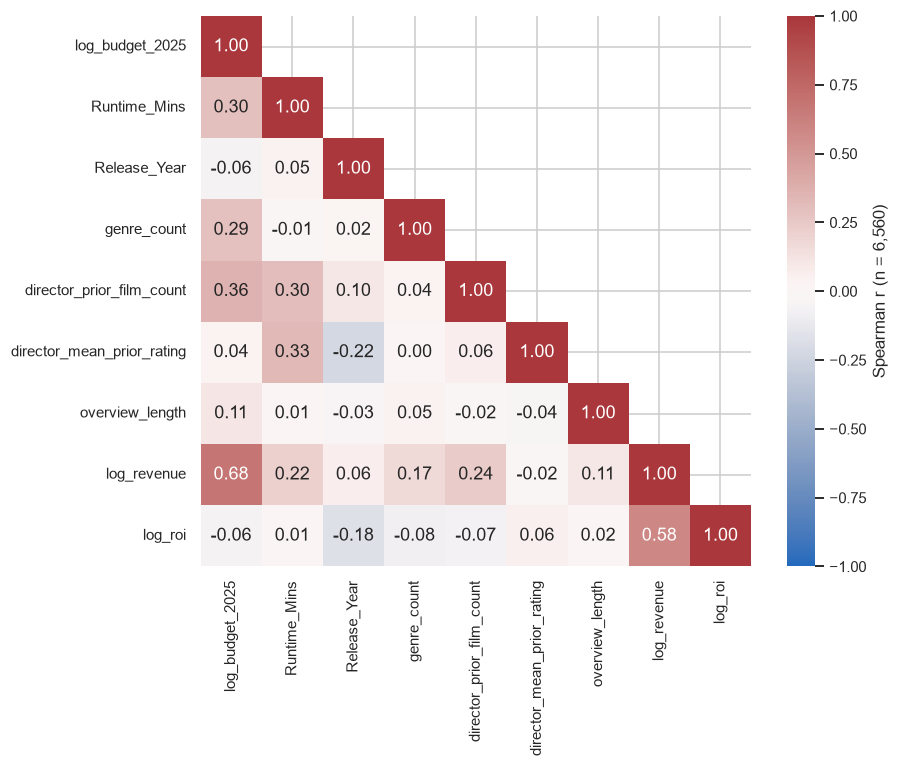

predictor pairs with |Spearman r| > 0.8: 0


In [70]:
corr_cols = num + ["log_revenue", "log_roi"]
cm = diag[corr_cols].astype("float64").corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(cm, dtype=bool), k=1)
sns.heatmap(cm, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True,
            cbar_kws={"label": f"Spearman r (n = {len(diag):,})"}, ax=ax)
save_fig(fig, "fig4_1_feature_corr")
plt.show()

pairs = cm.where(~np.eye(len(cm), dtype=bool)).abs()
high = pairs[num].loc[num].stack()
high = high[high > 0.8]
stats["collinear_pairs_over_0p8"] = int(len(high) // 2)
print("predictor pairs with |Spearman r| > 0.8:", len(high) // 2)

#### 2. Variance inflation factors

VIF on the standardised numeric block (with intercept). The usual worry
threshold is 5.

In [71]:
from sklearn.preprocessing import StandardScaler

vif_X = X[num + ["debut_director"]].copy()
vif_X = pd.DataFrame(StandardScaler().fit_transform(vif_X), columns=vif_X.columns)
vif_X.insert(0, "const", 1.0)
vif = pd.Series(
    [variance_inflation_factor(vif_X.values, i) for i in range(1, vif_X.shape[1])],
    index=vif_X.columns[1:], name="VIF",
).sort_values(ascending=False)
stats["max_vif"] = round(float(vif.drop("debut_director").max()), 2)
# VIF on the numeric block alone cannot see one exact dependency: genre_count
# is the row sum of the one-hot genre flags. Verify it, because it means the
# two cannot both enter a linear model.
flag_sum = diag[genre_cols].astype(int).sum(axis=1)
exact = bool((flag_sum == diag["genre_count"].astype(int)).all())
stats["genre_count_equals_flag_sum"] = "yes" if exact else "no"
assert exact
print("genre_count == sum of one-hot genre flags for every film:", exact)

vif_tex = vif.reset_index()
vif_tex.columns = ["feature", "VIF"]
vif_tex["VIF"] = vif_tex["VIF"].map(lambda v: f"{v:.2f}")
write_table(vif_tex, "tab4_1_vif")
vif.round(2)

genre_count == sum of one-hot genre flags for every film: True


debut_director                1.41
log_budget_2025               1.33
director_prior_film_count     1.32
Runtime_Mins                  1.24
director_mean_prior_rating    1.15
genre_count                   1.10
Release_Year                  1.07
overview_length               1.02
Name: VIF, dtype: float64

`director_mean_prior_rating` and `debut_director` are mechanically
coupled (the indicator marks exactly the rows whose rating was filled),
which inflates that pair; among the real predictors no VIF approaches 5,
so the numeric block carries no harmful collinearity.

**But the numeric-block VIF misses one exact dependency**, verified
above: `genre_count` is the row sum of the one-hot genre flags. A first
draft of the Chapter 5 OLS included both, and its genre coefficients came
out unidentified (shifting by ~3 between runs). `genre_count` is
therefore dropped from every model; the flags are kept.

#### 3. Mutual information against each target

Nonparametric dependence of every candidate feature on each of the three
Chapter 5 targets. `Total_Votes` is added **only** to demonstrate the
leakage it would cause — it is barred from the models.

In [72]:
Xmi = X.copy()
Xmi["Total_Votes_LEAKY"] = diag.loc[X.index, "Total_Votes"].astype("float64")
discrete = np.array([c in binary + genre_cols for c in Xmi.columns])

y_rev = diag.loc[X.index, "log_revenue"]
y_roi = diag.loc[X.index, "log_roi"]
y_prof = diag.loc[X.index, "is_profitable"].astype(bool)

mi = pd.DataFrame(
    {
        "log1p(revenue)": mutual_info_regression(Xmi, y_rev, discrete_features=discrete, random_state=0),
        "log(ROI)": mutual_info_regression(Xmi, y_roi, discrete_features=discrete, random_state=0),
        "is_profitable": mutual_info_classif(Xmi, y_prof, discrete_features=discrete, random_state=0),
    },
    index=Xmi.columns,
)
mi_sorted = mi.sort_values("log1p(revenue)", ascending=False)
stats["mi_top_revenue_feature"] = str(mi.drop(index="Total_Votes_LEAKY")["log1p(revenue)"].idxmax())
stats["mi_budget_revenue"] = round(float(mi.loc["log_budget_2025", "log1p(revenue)"]), 3)
stats["mi_budget_roi"] = round(float(mi.loc["log_budget_2025", "log(ROI)"]), 3)
stats["mi_votes_revenue_leaky"] = round(float(mi.loc["Total_Votes_LEAKY", "log1p(revenue)"]), 3)
stats["mi_votes_roi_leaky"] = round(float(mi.loc["Total_Votes_LEAKY", "log(ROI)"]), 3)
stats["mi_votes_profitable_leaky"] = round(float(mi.loc["Total_Votes_LEAKY", "is_profitable"]), 3)
best_legit_prof = mi.drop(index="Total_Votes_LEAKY")["is_profitable"].max()
stats["mi_best_legit_profitable"] = round(float(best_legit_prof), 3)
stats["mi_leak_ratio_profitable"] = round(float(mi.loc["Total_Votes_LEAKY", "is_profitable"] / best_legit_prof), 1)
stats["mi_roi_to_revenue_ratio_budget"] = round(
    float(mi.loc["log_budget_2025", "log(ROI)"] / mi.loc["log_budget_2025", "log1p(revenue)"]), 2)

mi_tex = mi_sorted.head(12).reset_index(names="feature")
for c in ["log1p(revenue)", "log(ROI)", "is_profitable"]:
    mi_tex[c] = mi_tex[c].map(lambda v: f"{v:.3f}")
mi_tex["feature"] = mi_tex["feature"].str.replace("_LEAKY", " (barred)", regex=False)
write_table(mi_tex, "tab4_2_mutual_info")
mi_sorted.round(3).head(12)

,log1p(revenue),log(ROI),is_profitable
Total_Votes_LEAKY,0.357,0.107,0.080
log_budget_2025,0.347,0.068,0.009
Release_Year,0.062,0.043,0.003
genre_adventure,0.052,0.001,0.001
director_mean_prior_rating,0.047,0.026,0.007
genre_action,0.028,0.000,0.000
genre_family,0.028,0.006,0.004
is_english,0.028,0.000,0.001
genre_count,0.027,0.009,0.000
genre_drama,0.026,0.008,0.004


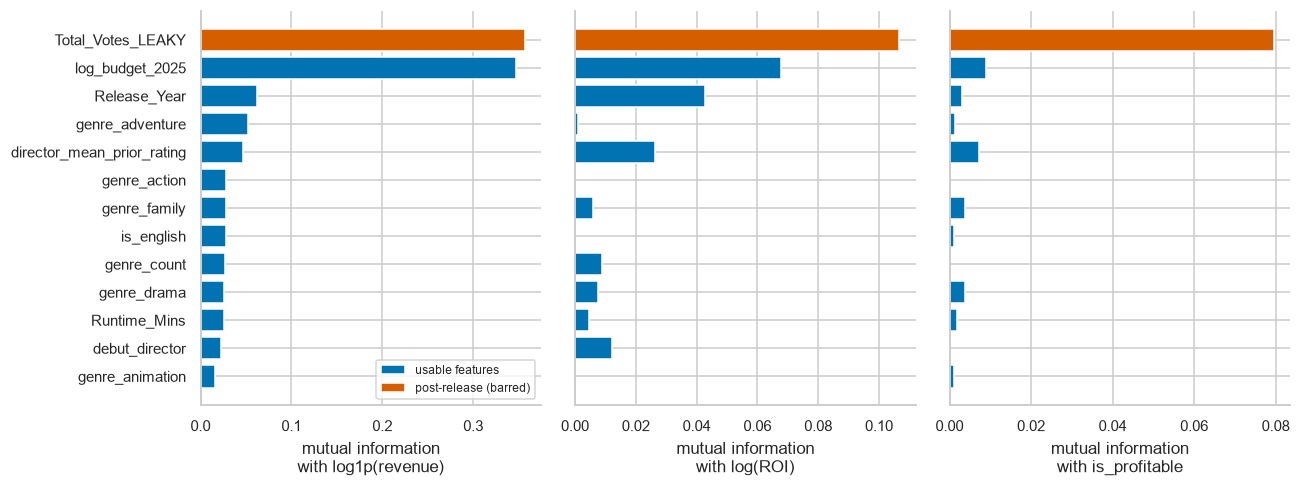

In [73]:
top = mi_sorted.drop(index="Total_Votes_LEAKY").head(12).iloc[::-1]
leak = mi_sorted.loc[["Total_Votes_LEAKY"]]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharey=True)
for ax, col in zip(axes, mi.columns):
    ax.barh(top.index, top[col], color="C0", label="usable features")
    ax.barh(leak.index, leak[col], color="C3", label="post-release (barred)")
    ax.set_xlabel(f"mutual information\nwith {col}")
axes[0].legend(loc="lower right", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig4_2_mutual_info")
plt.show()

#### Selection decisions

- **Kept**: deflated log budget, runtime, one-hot genres, language, the
  two release-window flags, director history pair, studio tier, content
  rating, overview length. No pair exceeds the correlation filter and no
  real VIF approaches 5. Release year is kept for description but not
  used as a predictor under the year-based split (Chapter 5 explains).
- **Dropped as an exact linear combination**: `genre_count` (= sum of
  the genre flags).
- **Barred as leakage**: `Total_Votes` and `Popularity_Score`. The red
  bar makes the case per target: on revenue, votes match the single best
  legitimate feature (0.357 vs budget's 0.347); on log(ROI) they carry
  ~1.6x the information of budget; and on `is_profitable` they carry
  roughly nine times the information of any legitimate feature — a
  signal that only exists because profitable films go on to collect
  votes. That is what post-release data does, and why it is barred.
- **Dropped as redundant**: `release_decade` and `release_quarter`
  duplicate year and month at coarser resolution; `profit` is a target
  transform, not a feature.
- The MI panels already preview Chapter 5's headline: every feature's
  information about **log(ROI)** is a fraction of its information about
  revenue — ROI is the harder target.

In [74]:
PROCESSED.mkdir(parents=True, exist_ok=True)
df.to_parquet(PROCESSED / "movies_features.parquet")
out = write_stats("ch04_features", stats)
print(f"wrote {PROCESSED / 'movies_features.parquet'}")
print(f"{len(stats)} statistics -> {out.relative_to(ROOT)}")
stats

wrote C:\EDA_Project\movie-success-eda\data\processed\movies_features.parquet
25 statistics -> report\stats\ch04_features.json


{'n_financial': 6560,
 'pct_profitable': 73.4,
 'director_check_matched': 500,
 'director_check_n': 500,
 'n_engineered': 33,
 'studio_tier_major': 2054,
 'studio_tier_mid': 3057,
 'studio_tier_indie': 4858,
 'tier_major_median_revenue_m': 83.4,
 'tier_mid_median_revenue_m': 46.8,
 'tier_indie_median_revenue_m': 16.9,
 'n_summer': 2288,
 'n_holiday': 1861,
 'collinear_pairs_over_0p8': 0,
 'max_vif': 1.33,
 'genre_count_equals_flag_sum': 'yes',
 'mi_top_revenue_feature': 'log_budget_2025',
 'mi_budget_revenue': 0.347,
 'mi_budget_roi': 0.068,
 'mi_votes_revenue_leaky': 0.357,
 'mi_votes_roi_leaky': 0.107,
 'mi_votes_profitable_leaky': 0.08,
 'mi_best_legit_profitable': 0.009,
 'mi_leak_ratio_profitable': 8.8,
 'mi_roi_to_revenue_ratio_budget': 0.2}

---
# Part 6 — Model fitting

*Report Chapter 5. Source notebook: `notebooks/06_modelling.ipynb`.*

## 06 — Model fitting

Models here measure **which pre-release attributes matter**; they are not
the point of the project. Three targets on the financial sample:

- `log1p(revenue)` in constant 2025 dollars (regression)
- `log(ROI)` (regression) — deflation cancels in the ratio
- `is_profitable` (classification)

**Honesty rules.** The train/test split is **by release year**, not
random: models are evaluated on films they could not have seen. All
imputation and scaling happens inside a `Pipeline`/`ColumnTransformer`
fitted on the training years only. Post-release variables (votes,
popularity) are excluded — Chapter 4 showed the leakage they carry. The
class balance is reported, and accuracy is never reported alone.

In [75]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats as sps
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve, root_mean_squared_error, r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan

from src.features import BINARY_PREDICTORS, CATEGORICAL_PREDICTORS, NUMERIC_PREDICTORS
from src.load import load_processed
from src.plotting import apply_style, save_fig
from src.reporting import fmt_int, fmt_p, write_stats, write_table

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

stats = {}

df = load_processed("movies_features")
fin = df[df["has_financials"] & ~df["is_future"]].copy()
fin = fin.dropna(subset=["Budget_2025usd", "Revenue_2025usd"])  # 1910s films without CPI
fin["log_revenue"] = np.log1p(fin["Revenue_2025usd"].astype("float64"))
fin["log_roi"] = np.log(fin["roi"].astype("float64"))
fin["log_budget_2025"] = np.log1p(fin["Budget_2025usd"].astype("float64"))
stats["n_model"] = len(fin)
print(f"modelling sample: {len(fin):,} films (complete financials, released <= 2025, CPI available)")

modelling sample: 6,560 films (complete financials, released <= 2025, CPI available)


### Train/test split by release year

The threshold is the 80th percentile of release years, so the test set is
the most recent fifth of films — the setting a studio actually faces:
predict the next years from the past.

In [76]:
split_year = int(fin["Release_Year"].astype("float64").quantile(0.8))
train = fin[fin["Release_Year"].astype("float64") <= split_year]
test = fin[fin["Release_Year"].astype("float64") > split_year]
stats.update(split_year=split_year, n_train=len(train), n_test=len(test))
print(f"train: {len(train):,} films (<= {split_year})   test: {len(test):,} films ({split_year + 1}–2025)")

train: 5,431 films (<= 2017)   test: 1,129 films (2018–2025)


### Features and preprocessing

The Chapter 4 feature set. `Release_Year` is dropped from the predictors
for the year-split models: with the test set strictly later than every
training film, a year coefficient would extrapolate outside its support
and silently absorb the split itself. `genre_count` is absent because it
is the exact sum of the genre flags (Chapter 4).

In [77]:
numeric = [c for c in NUMERIC_PREDICTORS if c not in ("Budget_2025usd", "Release_Year")] + ["log_budget_2025"]
binary = list(BINARY_PREDICTORS)
categorical = list(CATEGORICAL_PREDICTORS)
genre_cols = sorted(c for c in fin.columns if c.startswith("genre_") and c != "genre_count")
feature_cols = numeric + binary + genre_cols + categorical

def Xy(frame, target):
    X = frame[feature_cols].copy()
    for c in numeric:
        X[c] = X[c].astype("float64")
    for c in binary + genre_cols:
        X[c] = X[c].astype("float64")
    return X, frame[target].astype("float64" if target != "is_profitable" else "bool")

prep = ColumnTransformer(
    [
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), numeric),
        ("bin", "passthrough", binary + genre_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", drop="first"))]), categorical),
    ],
    verbose_feature_names_out=False,
)
print(f"{len(feature_cols)} input columns")

29 input columns


### Target 1 — log1p(revenue), constant 2025 dollars

#### OLS on the interpretable set

Fitted with statsmodels on the training years, numerics in natural units
(log budget keeps an elasticity reading: its coefficient is the % change
in revenue per 1% change in budget).

In [78]:
def ols_matrix(frame, med=None):
    X = frame[numeric + binary + genre_cols].copy()
    for c in X.columns:
        X[c] = X[c].astype("float64")
    X["debut_director"] = X["director_mean_prior_rating"].isna().astype(float)
    if med is None:
        med = X.median(numeric_only=True)
    X = X.fillna(med)
    tiers = pd.get_dummies(frame["studio_tier"], prefix="tier", drop_first=True).astype(float)
    X = pd.concat([X, tiers], axis=1)
    return sm.add_constant(X, has_constant="add"), med

X_tr_ols, med_tr = ols_matrix(train)
# Drop columns that are (near-)constant in the training years — they make
# the design matrix rank-deficient. Reported, not silent.
counts = (X_tr_ols.drop(columns="const") != 0).sum()
degenerate = counts[counts < 10].index.tolist()
if degenerate:
    print(f"dropped from OLS (fewer than 10 non-zero training rows): {degenerate}")
    X_tr_ols = X_tr_ols.drop(columns=degenerate)
stats["ols_dropped_degenerate"] = ", ".join(degenerate) if degenerate else "none"
X_te_ols, _ = ols_matrix(test, med_tr)
X_te_ols = X_te_ols.reindex(columns=X_tr_ols.columns, fill_value=0.0)
y_tr = train["log_revenue"]
y_te = test["log_revenue"]

ols = sm.OLS(y_tr, X_tr_ols).fit()
bp_stat, bp_p, _, _ = het_breuschpagan(ols.resid, X_tr_ols)
stats["ols_rev_r2_train"] = round(float(ols.rsquared), 3)
stats["ols_rev_r2_test"] = round(float(r2_score(y_te, ols.predict(X_te_ols))), 3)
stats["ols_bp_p"] = float(bp_p)
print(f"Breusch-Pagan p = {bp_p:.2e} -> heteroscedastic, so inference below uses HC3 robust errors")

ols_r = sm.OLS(y_tr, X_tr_ols).fit(cov_type="HC3")
coef = pd.DataFrame({"coef": ols_r.params, "p (HC3)": ols_r.pvalues}).drop(index="const")
ci_all = ols_r.conf_int().drop(index="const")
coef["ci_lo"], coef["ci_hi"] = ci_all[0], ci_all[1]
top_coef = coef.reindex(coef["coef"].abs().sort_values(ascending=False).index).head(15)

coef_tex = top_coef.reset_index(names="term")
coef_tex = pd.DataFrame(
    {
        "term": coef_tex["term"],
        "coefficient": coef_tex["coef"].map(lambda v: f"{v:+.3f}"),
        "95% CI (HC3)": [f"[{lo:+.2f}, {hi:+.2f}]" for lo, hi in zip(coef_tex["ci_lo"], coef_tex["ci_hi"])],
        "p (HC3)": coef_tex["p (HC3)"].map(fmt_p),
    }
)
write_table(coef_tex, "tab5_1_ols_revenue_coefs", align="lrrr")
for term in ["tier_major", "tier_mid", "is_holiday_release", "is_summer_release", "is_english",
             "genre_documentary", "genre_animation", "genre_horror", "director_mean_prior_rating", "Runtime_Mins"]:
    if term in ols_r.params:
        stats[f"ols_coef_{term.lower()}"] = round(float(ols_r.params[term]), 3)
        stats[f"ols_p_{term.lower()}"] = float(ols_r.pvalues[term])
top_coef[["coef", "p (HC3)"]].round(3)

dropped from OLS (fewer than 10 non-zero training rows): ['genre_tv_movie']
Breusch-Pagan p = 3.94e-75 -> heteroscedastic, so inference below uses HC3 robust errors


,coef,p (HC3)
genre_documentary,0.871,0.001
log_budget_2025,0.698,0.000
tier_major,0.692,0.000
genre_western,-0.470,0.011
genre_drama,-0.392,0.000
tier_mid,0.360,0.000
genre_animation,0.329,0.000
genre_history,-0.256,0.003
genre_family,0.255,0.000
genre_science_fiction,-0.250,0.000


In [79]:
stats["ols_budget_elasticity"] = round(float(ols_r.params["log_budget_2025"]), 3)
stats["ols_budget_p"] = float(ols_r.pvalues["log_budget_2025"])
ci = ols_r.conf_int().loc["log_budget_2025"]
stats["ols_budget_ci_lo"] = round(float(ci[0]), 3)
stats["ols_budget_ci_hi"] = round(float(ci[1]), 3)
print(f"budget elasticity: {ols_r.params['log_budget_2025']:.3f} "
      f"[95% CI {ci[0]:.3f}, {ci[1]:.3f}], p = {ols_r.pvalues['log_budget_2025']:.1e}")
print(f"train R^2 = {stats['ols_rev_r2_train']}, test R^2 = {stats['ols_rev_r2_test']} (n test = {len(test):,})")

budget elasticity: 0.698 [95% CI 0.644, 0.752], p = 3.7e-141
train R^2 = 0.456, test R^2 = 0.361 (n test = 1,129)


#### OLS diagnostics

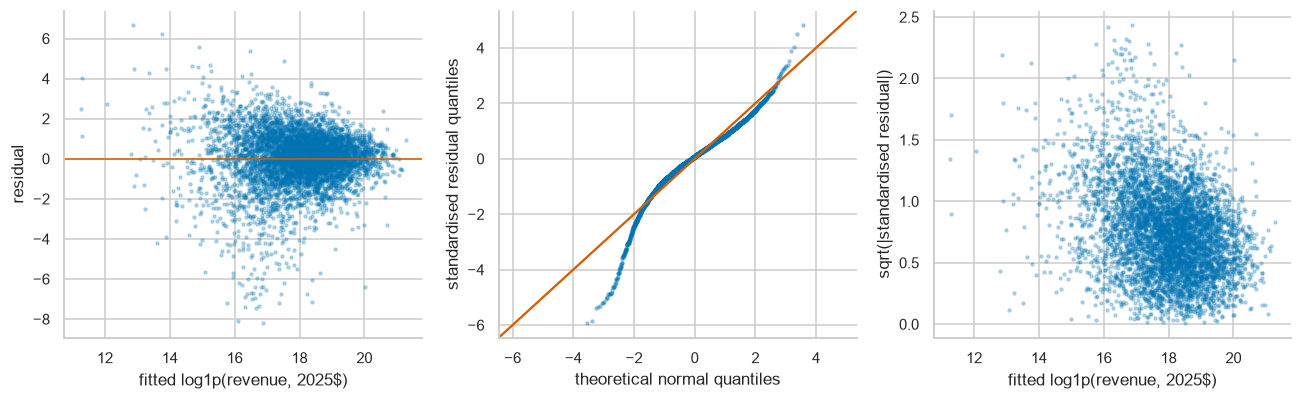

In [80]:
fitted = ols.fittedvalues
resid = ols.resid
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].scatter(fitted, resid, s=4, alpha=0.25)
axes[0].axhline(0, color="C3", lw=1)
axes[0].set_xlabel("fitted log1p(revenue, 2025$)")
axes[0].set_ylabel("residual")
sm.qqplot(resid, line="45", fit=True, ax=axes[1], markersize=2, alpha=0.3)
axes[1].set_xlabel("theoretical normal quantiles")
axes[1].set_ylabel("standardised residual quantiles")
axes[2].scatter(fitted, np.sqrt(np.abs(resid / resid.std())), s=4, alpha=0.25)
axes[2].set_xlabel("fitted log1p(revenue, 2025$)")
axes[2].set_ylabel("sqrt(|standardised residual|)")
fig.tight_layout()
save_fig(fig, "fig5_1_ols_diagnostics")
stats["ols_resid_skew"] = round(float(sps.skew(resid)), 2)
plt.show()

Residuals fan out at the low-fitted end and the Q-Q plot shows a heavy
left tail: the model misses worst on films that earned far *less* than
their attributes suggest — flops are idiosyncratic. Heteroscedasticity is
confirmed by Breusch-Pagan, hence the HC3 robust standard errors above.

#### Regularised and gradient-boosted comparisons

Ridge (alpha chosen by cross-validation inside the training years) and a
histogram gradient-boosted tree, both through the same leakage-safe
preprocessing. The boosted tree is the ceiling check: how much signal is
there beyond the linear fit?

In [81]:
X_tr, _ = Xy(train, "log_revenue")
X_te, _ = Xy(test, "log_revenue")

results = {}
models = {
    "OLS": None,  # filled from statsmodels above
    "Ridge": Pipeline([("prep", prep), ("m", RidgeCV(alphas=np.logspace(-3, 3, 25)))]),
    "HistGB": Pipeline([("prep", prep), ("m", HistGradientBoostingRegressor(random_state=0))]),
}
results["OLS"] = {
    "test_R2": stats["ols_rev_r2_test"],
    "test_RMSE": round(float(root_mean_squared_error(y_te, ols.predict(X_te_ols))), 3),
}
for name, pipe in models.items():
    if pipe is None:
        continue
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    results[name] = {
        "test_R2": round(float(r2_score(y_te, pred)), 3),
        "test_RMSE": round(float(root_mean_squared_error(y_te, pred)), 3),
    }
rev_results = pd.DataFrame(results).T
stats["ridge_rev_r2_test"] = float(rev_results.loc["Ridge", "test_R2"])
stats["gb_rev_r2_test"] = float(rev_results.loc["HistGB", "test_R2"])
stats["ols_rev_rmse_test"] = float(rev_results.loc["OLS", "test_RMSE"])
stats["ridge_rev_rmse_test"] = float(rev_results.loc["Ridge", "test_RMSE"])
rev_results

,test_R2,test_RMSE
OLS,0.361,1.716
Ridge,0.381,1.689
HistGB,0.364,1.712


### Target 2 — log(ROI)

Identical protocol, second target. Chapter 4's mutual information already
said this signal is weaker; here is how much weaker.

In [82]:
y_tr_roi = train["log_roi"]
y_te_roi = test["log_roi"]

ols_roi = sm.OLS(y_tr_roi, X_tr_ols).fit(cov_type="HC3")
roi_results = {
    "OLS": {
        "test_R2": round(float(r2_score(y_te_roi, ols_roi.predict(X_te_ols))), 3),
        "test_RMSE": round(float(root_mean_squared_error(y_te_roi, ols_roi.predict(X_te_ols))), 3),
    }
}
for name, maker in {
    "Ridge": lambda: Pipeline([("prep", prep), ("m", RidgeCV(alphas=np.logspace(-3, 3, 25)))]),
    "HistGB": lambda: Pipeline([("prep", prep), ("m", HistGradientBoostingRegressor(random_state=0))]),
}.items():
    pipe = maker()
    pipe.fit(X_tr, y_tr_roi)
    pred = pipe.predict(X_te)
    roi_results[name] = {
        "test_R2": round(float(r2_score(y_te_roi, pred)), 3),
        "test_RMSE": round(float(root_mean_squared_error(y_te_roi, pred)), 3),
    }
roi_results = pd.DataFrame(roi_results).T
stats["ols_roi_r2_test"] = float(roi_results.loc["OLS", "test_R2"])
stats["gb_roi_r2_test"] = float(roi_results.loc["HistGB", "test_R2"])
stats["roi_budget_coef"] = round(float(ols_roi.params["log_budget_2025"]), 3)
stats["roi_budget_p"] = float(ols_roi.pvalues["log_budget_2025"])
stats["ridge_roi_r2_test"] = float(roi_results.loc["Ridge", "test_R2"])
ci_roi = ols_roi.conf_int().loc["log_budget_2025"]
stats["roi_budget_ci_lo"] = round(float(ci_roi[0]), 3)
stats["roi_budget_ci_hi"] = round(float(ci_roi[1]), 3)

cmp_tex = pd.DataFrame(
    {
        "model": ["OLS", "Ridge (CV alpha)", "Gradient-boosted tree"],
        "R² log1p(revenue)": [f"{v:.3f}" for v in rev_results["test_R2"]],
        "RMSE log1p(revenue)": [f"{v:.3f}" for v in rev_results["test_RMSE"]],
        "R² log(ROI)": [f"{v:.3f}" for v in roi_results["test_R2"]],
        "RMSE log(ROI)": [f"{v:.3f}" for v in roi_results["test_RMSE"]],
    }
)
cmp_tex.columns = ["model", "$R^2$ revenue", "RMSE revenue", "$R^2$ ROI", "RMSE ROI"]
write_table(cmp_tex, "tab5_2_regression_comparison")
roi_results

,test_R2,test_RMSE
OLS,0.031,1.716
Ridge,0.061,1.689
HistGB,0.042,1.706


In [83]:
print(f"budget coefficient on log(ROI): {ols_roi.params['log_budget_2025']:.3f} "
      f"(p = {ols_roi.pvalues['log_budget_2025']:.1e})")

budget coefficient on log(ROI): -0.302 (p = 6.2e-28)


#### Predicted vs actual, both targets

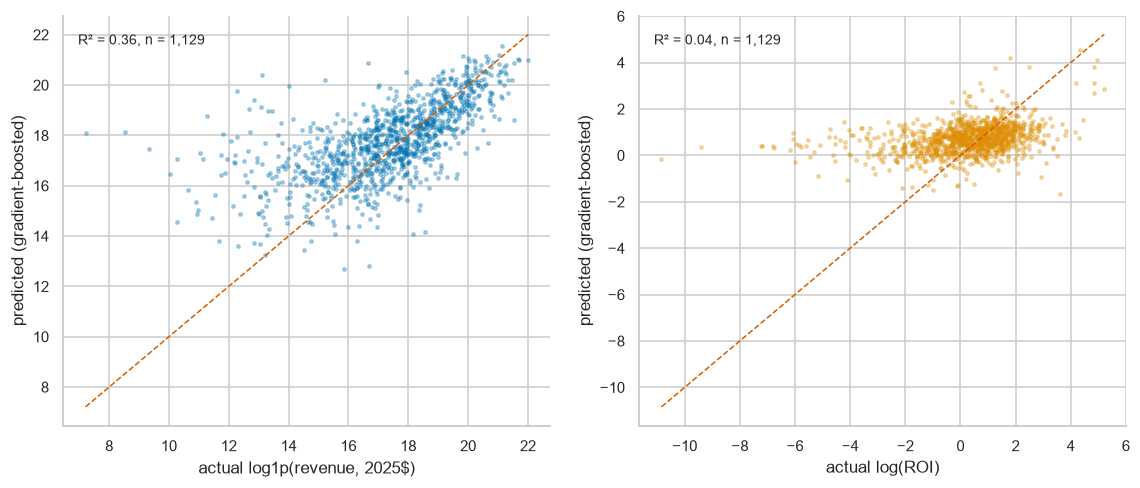

In [84]:
gb_rev = models["HistGB"]
pred_rev = gb_rev.predict(X_te)
gb_roi = Pipeline([("prep", prep), ("m", HistGradientBoostingRegressor(random_state=0))]).fit(X_tr, y_tr_roi)
pred_roi = gb_roi.predict(X_te)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
axes[0].scatter(y_te, pred_rev, s=5, alpha=0.3)
lims = [min(y_te.min(), pred_rev.min()), max(y_te.max(), pred_rev.max())]
axes[0].plot(lims, lims, color="C3", lw=1, ls="--")
axes[0].set_xlabel("actual log1p(revenue, 2025$)")
axes[0].set_ylabel("predicted (gradient-boosted)")
axes[0].annotate(f"R² = {stats['gb_rev_r2_test']:.2f}, n = {len(test):,}",
                 xy=(0.03, 0.93), xycoords="axes fraction", fontsize=9)
axes[1].scatter(y_te_roi, pred_roi, s=5, alpha=0.3, color="C1")
lims = [y_te_roi.min(), y_te_roi.max()]
axes[1].plot(lims, lims, color="C3", lw=1, ls="--")
axes[1].set_xlabel("actual log(ROI)")
axes[1].set_ylabel("predicted (gradient-boosted)")
axes[1].annotate(f"R² = {stats['gb_roi_r2_test']:.2f}, n = {len(test):,}",
                 xy=(0.03, 0.93), xycoords="axes fraction", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig5_2_pred_vs_actual")
plt.show()

### Target 3 — is_profitable (classification)

In [85]:
y_tr_c = train["is_profitable"].astype(bool)
y_te_c = test["is_profitable"].astype(bool)
stats["class_balance_train"] = round(float(y_tr_c.mean()) * 100, 1)
stats["class_balance_test"] = round(float(y_te_c.mean()) * 100, 1)
print(f"class balance (profitable): train {stats['class_balance_train']}%, test {stats['class_balance_test']}%")
print("-> a majority-class guesser already gets that accuracy; it is not reported as a result")

clf_results = {}
clfs = {
    "Logistic": Pipeline([("prep", prep), ("m", LogisticRegression(max_iter=2000))]),
    "HistGB": Pipeline([("prep", prep), ("m", HistGradientBoostingClassifier(random_state=0))]),
}
rocs = {}
for name, pipe in clfs.items():
    pipe.fit(X_tr, y_tr_c)
    prob = pipe.predict_proba(X_te)[:, 1]
    pred = prob >= 0.5
    clf_results[name] = {
        "precision": round(float(precision_score(y_te_c, pred)), 3),
        "recall": round(float(recall_score(y_te_c, pred)), 3),
        "F1": round(float(f1_score(y_te_c, pred)), 3),
        "ROC-AUC": round(float(roc_auc_score(y_te_c, prob)), 3),
    }
    rocs[name] = roc_curve(y_te_c, prob)
clf_results = pd.DataFrame(clf_results).T
stats["clf_best_auc"] = float(clf_results["ROC-AUC"].max())
stats["clf_best_f1"] = float(clf_results["F1"].max())

# The honest yardstick: a classifier that says "profitable" for every film
pred_all_true = np.ones(len(y_te_c), dtype=bool)
stats["majority_baseline_f1"] = round(float(f1_score(y_te_c, pred_all_true)), 3)
print(f"majority-baseline F1 (predict 'profitable' always): {stats['majority_baseline_f1']}")
print("-> F1 barely beats that baseline; the evidence of real ranking skill is the AUC")
for name in clf_results.index:
    for metric in ["precision", "recall"]:
        stats[f"clf_{name.lower()}_{metric}"] = float(clf_results.loc[name, metric])
    stats[f"clf_{name.lower()}_auc"] = float(clf_results.loc[name, "ROC-AUC"])
    stats[f"clf_{name.lower()}_f1"] = float(clf_results.loc[name, "F1"])

clf_tex = clf_results.reset_index(names="model")
clf_tex.loc[len(clf_tex)] = ["Always 'profitable' (baseline)", float(y_te_c.mean()), 1.0,
                             stats["majority_baseline_f1"], 0.5]
for c in ["precision", "recall", "F1", "ROC-AUC"]:
    clf_tex[c] = clf_tex[c].map(lambda v: f"{v:.3f}")
clf_tex["model"] = clf_tex["model"].replace({"Logistic": "Logistic regression",
                                             "HistGB": "Gradient-boosted tree"})
write_table(clf_tex, "tab5_3_classification")
clf_results

class balance (profitable): train 75.4%, test 63.9%
-> a majority-class guesser already gets that accuracy; it is not reported as a result


majority-baseline F1 (predict 'profitable' always): 0.779
-> F1 barely beats that baseline; the evidence of real ranking skill is the AUC


,precision,recall,F1,ROC-AUC
Logistic,0.647,0.990,0.783,0.682
HistGB,0.659,0.956,0.780,0.643


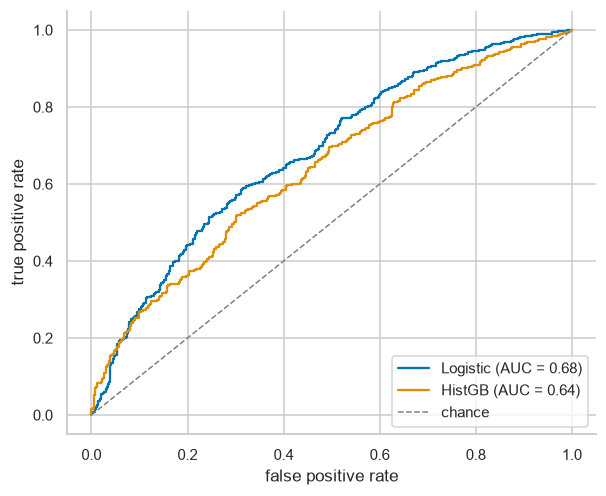

In [86]:
fig, ax = plt.subplots(figsize=(6.2, 5))
for name, (fpr, tpr, _) in rocs.items():
    ax.plot(fpr, tpr, label=f"{name} (AUC = {clf_results.loc[name, 'ROC-AUC']:.2f})")
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="chance")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.legend(loc="lower right")
save_fig(fig, "fig5_3_roc")
plt.show()

### Which features matter — permutation importance

Importance on the held-out years for the gradient-boosted revenue model:
how much test R² is lost when each feature is shuffled.

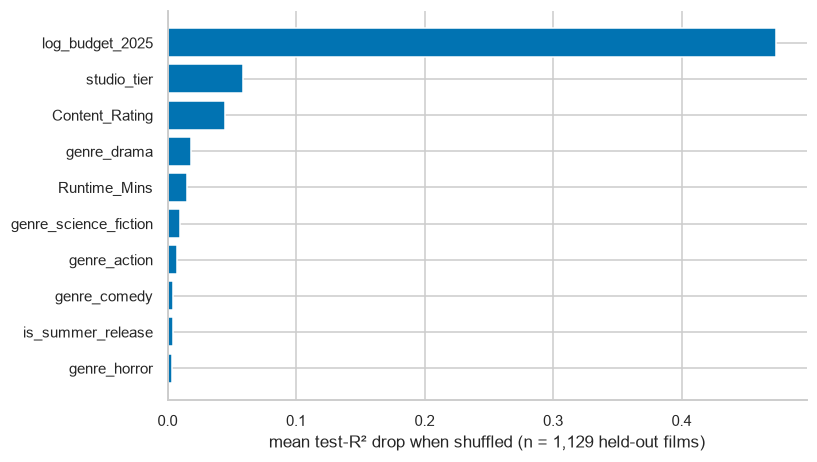

log_budget_2025          0.474
studio_tier              0.058
Content_Rating           0.045
genre_drama              0.018
Runtime_Mins             0.015
genre_science_fiction    0.010
genre_action             0.007
genre_comedy             0.004
is_summer_release        0.004
genre_horror             0.004
dtype: float64

In [87]:
pi = permutation_importance(gb_rev, X_te, y_te, n_repeats=10, random_state=0, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False)
stats["perm_top_feature"] = str(imp.index[0])
stats["perm_top_drop"] = round(float(imp.iloc[0]), 3)
stats["perm_second_drop"] = round(float(imp.iloc[1]), 3)
stats["perm_second_feature"] = str(imp.index[1])

top10 = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(top10.index, top10.values, color="C0")
ax.set_xlabel(f"mean test-R² drop when shuffled (n = {len(test):,} held-out films)")
save_fig(fig, "fig5_4_permutation_importance")
plt.show()
imp.head(10).round(3)

In [88]:
out = write_stats("ch05_modelling", stats)
print(f"{len(stats)} statistics -> {out.relative_to(ROOT)}")
stats

61 statistics -> report\stats\ch05_modelling.json


{'n_model': 6560,
 'split_year': 2017,
 'n_train': 5431,
 'n_test': 1129,
 'ols_dropped_degenerate': 'genre_tv_movie',
 'ols_rev_r2_train': 0.456,
 'ols_rev_r2_test': 0.361,
 'ols_bp_p': 3.938224320379909e-75,
 'ols_coef_tier_major': 0.692,
 'ols_p_tier_major': 5.08339259149509e-46,
 'ols_coef_tier_mid': 0.36,
 'ols_p_tier_mid': 7.238166303752706e-12,
 'ols_coef_is_holiday_release': 0.234,
 'ols_p_is_holiday_release': 2.098218878819932e-06,
 'ols_coef_is_summer_release': 0.198,
 'ols_p_is_summer_release': 3.386404645773045e-05,
 'ols_coef_is_english': 0.224,
 'ols_p_is_english': 0.005742604954605668,
 'ols_coef_genre_documentary': 0.871,
 'ols_p_genre_documentary': 0.0011506242145084935,
 'ols_coef_genre_animation': 0.329,
 'ols_p_genre_animation': 0.00027256429471265314,
 'ols_coef_genre_horror': -0.108,
 'ols_p_genre_horror': 0.18171121401355095,
 'ols_coef_director_mean_prior_rating': 0.128,
 'ols_p_director_mean_prior_rating': 0.005389675725328389,
 'ols_coef_runtime_mins': 0.011,


### What the models say (carried to the report)

Numbers quoted from `report/stats/ch05_modelling.json`; the prose
observations here are confirmed against the executed outputs above.

Exact values are in `report/stats/ch05_modelling.json` and the tables
above; the report quotes them from there.

- Revenue is moderately predictable from pre-release attributes alone;
  **log(ROI) is almost unpredictable** across every model class. The gap
  is the finding: what a film *is* largely determines the scale of its
  gross, but how much it returns per dollar depends on things outside
  these attributes — plausibly marketing, release competition and word
  of mouth, none of which the data contains.
- The gradient-boosted tree does not beat the regularised linear model
  on either target, so there is little non-linear signal beyond the
  linear fit and the OLS coefficients are a fair summary.
- Budget dominates revenue in both the OLS elasticity (below 1: bigger
  budgets are associated with less-than-proportionally bigger gross) and
  the permutation importances. Its coefficient on log(ROI) is negative:
  bigger budgets are associated with *lower* returns per dollar.
- The classifier's F1 barely clears the predict-always-profitable
  baseline; its AUC shows modest real ranking skill. The profitable share
  itself falls between the training and test years, consistent with
  Chapter 3's declining-ROI decade trend.

---
# Conclusions

The answers to the research questions, with every number, are in Chapter 6 of the report (`report/template2026.pdf`). Every figure and statistic quoted there was produced by the cells above.